# 03 · Self-supervised temporal movement encoder

**Advanced movement representation learning — chapter 3.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-11). No cell has been run by the author.

## Research question
**Can a neural network discover a stable, athlete-specific movement signature beyond what official Combine results and recording artifacts already explain?**

The question is not whether a network reconstructs sprint curves better than functional PCA. A lower reconstruction error is reported and never decides anything.

## Method in short
1. **Same data as notebook 02.** The curves, the fold registry, the support rule and the eligibility rule are those of the FPCA baseline. Nothing is rebuilt.
2. **One compact encoder per input**, never combined: A speed against recorded distance (primary), B tangential acceleration against speed (secondary), C speed against elapsed time (control).
3. **Two objectives.** TCN-A: reconstruct recorded points hidden on purpose. TCN-B: the same plus a consistency term between two attempts of the same training athlete.
4. **Inductive evaluation.** For every outer fold the encoder is trained on the training athletes, stopped on an inner development fold, frozen, and applied to the held-out athletes.
5. **One evaluation for every method**, FPCA included: repeat-attempt discrimination and retrieval, collapse diagnostics, probes for official results, cohort and recording window, residual repeatability, truncation stability.
6. **Go / no-go** read on confirm-role athletes against the FPCA of the same input.

## Inputs (same `RUN_MODE` as notebooks 00–02)
`sequence_manifest`, `athlete_registry`, `split_registry` (notebook 00); `sequence_frames`, `sequence_summary` (notebook 01); `sequence_window_flags`, `preprocessing_audit`, the `fpca_*` tables and the fitted FPCA fold models (notebook 02).

## What this notebook does not do
No NFL value is read and no NFL predictive value is claimed. No hyperparameter search: the architecture is fixed, and the only tuned quantity (the consistency term) is chosen on design-role athletes. PyTorch must already be installed in the kernel; nothing is installed from here.

## Configuration

In [1]:
# %pip install torch

In [2]:
RUN_MODE = 'full'      # 'smoke' | 'full' — must match the mode notebooks 00, 01 and 02 were run with
FORCE_REBUILD = False   # True = retrain and recompute even when cached tables and checkpoints are current
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True      # fold checkpoints under artifacts/models/advanced_movement/tcn
DEVICE = 'auto'         # 'auto' | 'cpu' | 'cuda' (the models are small: CPU is enough)
SEED = 20261011         # same seed as notebook 00
NUM_WORKERS = 0         # unused: the curves of a fold fit in memory as one tensor
BATCH_SIZE = 32         # ATHLETES per batch; each brings at most two attempts
MAX_EPOCHS = 200        # upper bound; early stopping usually ends sooner. Smoke mode caps it at 12
RUN_SENSITIVITY_16 = True   # also train 16-dimensional encoders on input A (sensitivity only, never selected)

In [3]:
from dataclasses import asdict, replace

from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc

dependencies = pl.DataFrame(amc.check_dependencies())
display(dependencies)
if dependencies.filter((pl.col('package') == 'torch') & (pl.col('status') != 'ok')).height:
    raise amc.DependencyError('PyTorch is not installed in this kernel. Install it yourself into the project environment '
                              '(a CPU build is enough), restart the kernel and run this notebook again. Nothing is installed from here.')

import torch

from nflbdb.data.utils import read_json
from nflbdb.features.config import KinematicsConfig
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import eda
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import repr_eval as rv
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import tcn
from nflbdb.research.advanced_movement import tcn_figures as tf
from nflbdb.research.advanced_movement import tcn_validation
from nflbdb.research.advanced_movement.artifacts import AdvStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
fcfg = fp.FpcaConfig().for_mode(controls)
ecfg = rv.EvalConfig().for_mode(controls)
store = AdvStore(cfg, controls)
device = amc.resolve_device(controls.device)
seed_notes = amc.seed_everything(controls.seed)
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(24)
pl.Config.set_fmt_str_lengths(240)

# Prerequisites: artifacts of notebooks 00–02 in the SAME run mode (smoke artifacts are never used for a full run).
NB00, NB01, NB02 = ('00_research_setup_and_data_audit.ipynb', '01_sequence_eda_and_alignment.ipynb',
                    '02_functional_pca_baseline.ipynb')
manifest = store.require(amd.MANIFEST, NB00)
athletes = store.require(amd.ATHLETES, NB00)
splits = store.require(amd.SPLITS, NB00)
seq_frames = store.require(seq.SEQ_FRAMES, NB01)
summary = store.require(eda.SUMMARY, NB01)
windows = store.require(ck.WINDOWS, NB02)
audit = store.require(ck.AUDIT, NB02)
fpca_summary = store.require(fe.SUMMARY, NB02)
fpca_gate = store.require(fe.GATE, NB02)
previous = store.read_json('research_metadata', NB00)
if previous.get('seed') != controls.seed:
    seed_00 = previous.get('seed')
    raise ValueError(f'SEED = {controls.seed} but notebook 00 was run with seed {seed_00}: use the same seed')

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
half_window = KinematicsConfig().smoothing.window // 2     # Savitzky–Golay half-window of the persisted kinematics
roles = splits.filter(pl.col('repeat') == 0).group_by('design_role').len().sort('design_role')
n_design, n_confirm = (int(roles.filter(pl.col('design_role') == r)['len'].sum()) for r in ('design', 'confirm'))
label = 'TECHNICAL CHECK ONLY — a few athletes and epochs; no number below is a result' if controls.smoke else 'full population'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {ss.n} sequences of {np.unique(ss.nfl_ids).size} athletes · '
                 f'{n_design} design / {n_confirm} confirm athletes · device `{device}` · torch {torch.__version__}'))
display(store.describe())

package,version,status,needed_for
str,str,str,str
"""numpy""","""2.2.6""","""ok""","""all notebooks"""
"""polars""","""2.0.0""","""ok""","""all notebooks"""
"""duckdb""","""1.5.6""","""ok""","""all notebooks"""
"""pyarrow""","""25.0.1""","""ok""","""all notebooks"""
"""matplotlib""","""3.10.7""","""ok""","""all notebooks"""
"""psutil""","""7.1.0""","""ok""","""all notebooks"""
"""torch""","""2.14.1+cpu""","""ok""","""notebook 03 onwards (TCN, GRU,…"


**Run mode: `full`** (full population) · 793 sequences of 418 athletes · 125 design / 293 confirm athletes · device `cpu` · torch 2.14.1+cpu

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_movement"""
"""datasets (Parquet + schema sidecar)""","""warehouse/gold/advanced_movement"""
"""figures (PNG 300 DPI, SVG, PDF)""","""reports/figures/advanced_movement"""
"""models and fitted preprocessing""","""artifacts/models/advanced_movement"""


## 1 · Research overview

### What a useful representation must show

| # | Property | How it is measured here (held-out athletes only) |
|---|---|---|
| 1 | Repeatable across an athlete's attempts | distance between his two attempts against distances to other athletes (AUC, retrieval), trace reliability |
| 2 | Discriminative within position | every gallery is restricted to athletes of the same position |
| 3 | Not an encoding of the official forty | held-out probes; repeatability of what is left after removing official results |
| 4 | Robust to the recording window | attempt-to-attempt change explained by the window; embedding shift under controlled truncation |
| 5 | Robust to the draft cohort | cohort probe beyond position; repeatability inside each cohort |
| 6 | Stable on athletes excluded from training | everything above is computed on athletes no part of the model has seen |

### Two kinds of held-out, kept apart

The split registry of notebook 00 carries two things, with different purposes.

| Mechanism | Purpose | Use in this notebook |
|---|---|---|
| **Outer folds** (5, athlete-grouped) | every athlete is embedded by a model that never saw him | training and evaluation of every encoder; same folds as the FPCA |
| **Inner fold** inside each outer training set | a development set that is not the held-out fold | early stopping only |
| **Design role** (about 30 % of athletes) | athletes on whom modelling choices may be made | the consistency kind and weight of TCN-B are chosen here, by cross-fitting inside the design athletes |
| **Confirm role** (the rest) | athletes who took no part in any choice | the read-out of the go / no-go: metrics on confirm athletes, each embedded by the fold model that excluded him |

A confirm athlete does appear in the training set of the four folds that do not evaluate him. That is the inductive protocol and is not a leak: his own embedding always comes from the fifth model. What the confirm role guarantees is different: no confirm athlete influenced a hyperparameter, an architecture or an augmentation. Design athletes are also evaluated out of fold, but they are reported separately because the consistency term was chosen on them.

Nothing in this notebook is to be re-tuned after its confirm results have been read.

### Why embeddings are compared through distances

Five folds mean five independently trained encoders, and dimension 3 of one is not dimension 3 of another. No statistic here compares a coordinate across folds. Distances, ranks and regressions are computed inside one fold and then pooled; the reliability summary is a trace, unchanged by a rotation of the embedding.

## 2 · Previously established FPCA findings

Notebook 02 was executed in full mode on 2026-10-11 (793 forty-yard sequences, 418 athletes, 375 with a repeat). Its saved tables give, within position, on out-of-fold scores:

| Representation | K | Held-out FVE | RMSE | Component | ICC [95 %] | \|ρ\| official times | Window share of attempt change | Label |
|---|---|---|---|---|---|---|---|---|
| A · speed against distance | 2 | 0.975 | 0.101 yd/s | 1 | 0.95 [0.94, 0.96] | 0.93 | 0.32 | redundant with the stopwatch |
| | | | | 2 | 0.36 [0.19, 0.47] | 0.13 | 0.59 | not repeatable |
| B · acceleration against speed | 5 | 0.964 | 0.162 yd/s² | 1 | 0.53 [0.35, 0.70] | 0.61 | 0.15 | inconclusive |
| | | | | 2–5 | 0.41 to 0.18 | 0.14 to 0.20 | 0.13 to 0.01 | not repeatable |
| C · speed against elapsed time | 2 | 0.962 | 0.152 yd/s | 1 | 0.42 [0.18, 0.71] | 0.65 | 0.95 | recording-window artifact |
| | | | | 2 | 0.37 [0.22, 0.45] | 0.27 | 0.31 | not repeatable |

These are functional PCA results. No component combines strong repeatability, low stopwatch redundancy and low window dependence: the repeatable one (A1) is the stopwatch, the non-redundant ones are not repeatable, and the clock-based one follows the recording.

The cell below reloads the same tables for the current run mode, so the reference shown beside the encoders is the one on disk and not the text above.

In [4]:
MAIN = [s.name for s in fp.MAIN]
K = {r['representation']: int(r['k_selected']) for r in fpca_summary.iter_rows(named=True) if r['representation'] in MAIN}
display(Markdown('**FPCA benchmark at the K selected in notebook 02** (this run mode)'))
display(fpca_summary.filter(pl.col('representation').is_in(MAIN)).select(
    'representation', 'role', 'k_selected', 'fve_heldout', 'rmse_heldout', 'value_unit', 'n_athletes_scored', 'n_athletes_repeat',
    'r2_forty_from_scores'))
display(fpca_gate.filter(pl.col('representation').is_in(MAIN)).select(
    'representation', 'component', 'explained_ratio', 'icc_adj', 'icc_lower', 'icc_upper', 'redundancy_abs', 'r2_stopwatch',
    'window_r2_within', 'cohort_r2', 'status'))

**FPCA benchmark at the K selected in notebook 02** (this run mode)

representation,role,k_selected,fve_heldout,rmse_heldout,value_unit,n_athletes_scored,n_athletes_repeat,r2_forty_from_scores
str,str,i64,f64,f64,str,i64,i64,f64
"""A_speed_by_distance""","""primary""",2,0.974672,0.100867,"""yd/s""",418,375,0.916237
"""B_accel_by_speed""","""secondary""",5,0.964133,0.162087,"""yd/s²""",418,375,0.545277
"""C_speed_by_time""","""control""",2,0.962225,0.152378,"""yd/s""",418,375,0.651297


representation,component,explained_ratio,icc_adj,icc_lower,icc_upper,redundancy_abs,r2_stopwatch,window_r2_within,cohort_r2,status
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""A_speed_by_distance""",1,0.930446,0.953262,0.937165,0.962957,0.930249,0.916159,0.321688,0.001429,"""redundant_with_stopwatch"""
"""A_speed_by_distance""",2,0.046714,0.357969,0.194068,0.469359,0.127711,0.020097,0.593982,0.086973,"""not_repeatable"""
"""B_accel_by_speed""",1,0.783923,0.534109,0.353402,0.69733,0.606001,0.408358,0.148536,0.10595,"""inconclusive"""
"""B_accel_by_speed""",2,0.114358,0.409325,0.265203,0.480844,0.202749,0.02966,0.128691,0.146432,"""not_repeatable"""
"""B_accel_by_speed""",3,0.030625,0.310254,0.138969,0.415228,0.183528,0.042679,0.060438,0.121308,"""not_repeatable"""
"""B_accel_by_speed""",4,0.019402,0.187617,-0.010752,0.303939,0.137893,0.009856,0.027763,0.001503,"""not_repeatable"""
"""B_accel_by_speed""",5,0.012833,0.175786,0.022624,0.284976,0.183829,0.029848,0.012524,0.021018,"""not_repeatable"""
"""C_speed_by_time""",1,0.77113,0.417478,0.179597,0.708681,0.648392,0.451752,0.95051,0.028217,"""window_artifact"""
"""C_speed_by_time""",2,0.194579,0.370222,0.219516,0.454442,0.269157,0.049486,0.308626,0.120599,"""not_repeatable"""


## 3 · Experiment configuration

Everything that defines the experiment is in the next cell. The architecture, the optimiser, the masking and the noise are fixed before any fit. Two things are compared and nothing else:

- the **consistency term** of TCN-B (kind and weight), on design athletes, for input A only; the choice is then applied unchanged to inputs B and C;
- the **embedding size** 8 against 16, as a declared sensitivity on input A. The 16-dimensional encoders are reported and never selected.

The evaluation uses split repeat 0, the repeat on which notebook 02 puts its intervals.

In [5]:
REPRESENTATIONS = MAIN                      # one single-input encoder each; inputs are never combined
PRIMARY = 'A_speed_by_distance'
REPEATS = [0]                               # split repeat evaluated (an athlete is then held out exactly once)

# TCN-A. Eligibility and support rules are the FPCA rules of notebook 02.
tcfg_a = tcn.TcnConfig(objective=tcn.RECON, min_coverage=fcfg.min_coverage,
                       min_observed_fraction=fcfg.min_observed_fraction).for_mode(controls)

# TCN-B: candidates of the consistency term, ranked on DESIGN athletes only (section 10).
CONSISTENCY_DEFAULT = ('vicreg', 0.3)       # kept when the design athletes cannot rank the candidates
CONSISTENCY_GRID = [('vicreg', 0.1), ('vicreg', 0.3), ('vicreg', 1.0), ('mse', 0.1), ('mse', 0.3), ('mse', 1.0)]
if controls.smoke:
    CONSISTENCY_GRID = [('vicreg', 0.3), ('mse', 0.3)]

fpca_specs = [rv.fpca_method(name, K[name]) for name in REPRESENTATIONS]
display(Markdown('**Encoder and optimisation** (identical for every input and both objectives)'))
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in tcfg_a.params().items()]))
display(Markdown('**Evaluation**'))
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in ecfg.params().items()]))
display(Markdown('**Augmentations: used and excluded, with the reason**'))
display(pl.DataFrame([{'transformation': a, 'status': b, 'justification': c} for a, b, c in tcn.AUGMENTATIONS]))
display(Markdown('**Sources of remaining nondeterminism**: ' + '; '.join(seed_notes)))

**Encoder and optimisation** (identical for every input and both objectives)

parameter,value
str,str
"""version""","""1"""
"""objective""","""reconstruction"""
"""embedding_dim""","""8"""
"""hidden""","""32"""
"""kernel_size""","""5"""
"""dilations""","""[1, 2, 4]"""
"""dropout""","""0.1"""
"""decoder_hidden""","""64"""
"""lr""","""0.002"""


**Evaluation**

parameter,value
str,str
"""version""","""1"""
"""top_k""","""5"""
"""ridge_alpha""","""1.0"""
"""probe_folds""","""5"""
"""truncations""","""(('head', 0.15), ('head', 0.3), ('tail', 0.15), ('tail', 0.3))"""
"""near_identical""","""0.01"""
"""collapse_rank_share""","""0.25"""
"""collapse_identical_share""","""0.05"""
"""margin_auc""","""0.02"""


**Augmentations: used and excluded, with the reason**

transformation,status,justification
str,str,str
"""span masking of recorded points""","""used (the task)""","""Hides about 30 % of an attempt's recorded points in two contiguous runs; the values stay those measured. The athlete's curve is unchanged, only what the encoder may look at."""
"""edge masking (a shorter recording)""","""used (35 % of the runs touch the first or last recorded point)""","""Recordings start and stop at different moments of the run; hiding an end reproduces that difference without inventing a start. The hidden end remains a target, so the embedding must still describe the whole curve."""
"""additive noise at the measured noise level""","""used (input only, never the target)""","""SD = robust SD of the second differences of the training curves / √6, i.e. the point-to-point irregularity actually present in the training fold. Smaller than any difference between athletes by construction."""
"""pair views on the shared recorded range""","""used (TCN-B only)""","""Two attempts of one athlete are compared on the grid points both recordings hold. No region present in only one recording is treated as the same measurement."""
"""time warping""","""excluded""","""Changes how fast speed is gained — the acceleration profile is the trait under study."""
"""speed or amplitude scaling""","""excluded""","""Speed level is the main difference between athletes (and the stopwatch)."""
"""shifts of acceleration magnitude""","""excluded""","""Same reason: it is the signal, not a nuisance."""
"""mixing curves of different athletes or positions""","""excluded""","""Creates runs nobody produced and blurs athlete identity."""
"""simulated starts or extrapolated ends""","""excluded""","""Would be treated as measurements; nothing unrecorded is ever a target."""


**Sources of remaining nondeterminism**: Polars group_by output order is not guaranteed: every builder sorts explicitly; NumPy generators are created per task from the seed (no reliance on the global state); DataLoader workers > 0 change the order of random draws

## 4 · Input and artifact checks

The curves are rebuilt in memory from `sequence_frames` with the function notebook 02 used (a deterministic interpolation, no model). The fitted FPCA fold models are loaded from disk when their key matches the current inputs; otherwise they are refitted in memory, which gives the same models. The preprocessing audit of notebook 02 must show no failed blocking check.

In [6]:
ck.assert_blocking_passed(audit)
curves = {name: fp.build_curves(ss, acfg, fp.SPEC[name]) for name in REPRESENTATIONS}

# Key of the FPCA fit stage of notebook 02 (same parameters, same input files).
FPCA_PARAMS = {'config': acfg.params(), 'fpca': fcfg.params(), 'representations': [asdict(s) for s in fp.REPRESENTATIONS],
               'half_window': half_window, 'seed': controls.seed}
FPCA_FILES = [store.parquet(seq.SEQ_FRAMES), store.parquet(amd.SPLITS)]
FPCA_KEY = fe.fit_key(FPCA_PARAMS, FPCA_FILES)
on_disk = read_json(store.models_dir / 'fpca' / '_models.json', {}).get('key') == FPCA_KEY
fpca_models = fe.load_or_refit(store.models_dir, curves, splits, fcfg, FPCA_KEY)
source = 'loaded from the files of notebook 02' if on_disk else 'refitted in memory (no model file for this configuration; the fit is deterministic)'
display(Markdown(f'**FPCA fold models**: {source}.'))

checks = []
for name, cs in curves.items():
    seen = np.isfinite(cs.Y)
    reference = fpca_models[name]['reference']
    checks.append({'representation': name, 'role': fp.SPEC[name].role, 'axis': fp.SPEC[name].axis_label,
                   'value': fp.SPEC[name].value_label, 'grid_points': int(cs.grid.size), 'sequences': cs.n,
                   'sequences_with_data': int(seen.any(1).sum()), 'athletes': int(np.unique(cs.nfl_ids).size),
                   'share_observed': float(seen.mean()), 'fpca_k': K[name], 'fpca_fold_models': len(fpca_models[name]) - 1,
                   'fpca_components_available': reference.k_max})
    if K[name] > reference.k_max:
        raise ValueError(f'{name}: notebook 02 selected K = {K[name]} but the fitted models hold {reference.k_max} components')
display(pl.DataFrame(checks))
known = set(splits['nfl_id'].to_list())
orphans = sum(int(i) not in known for i in ss.nfl_ids)
if orphans:
    raise ValueError(f'{orphans} sequence(s) belong to an athlete without a fold: rerun notebook 00')

**FPCA fold models**: loaded from the files of notebook 02.

representation,role,axis,value,grid_points,sequences,sequences_with_data,athletes,share_observed,fpca_k,fpca_fold_models,fpca_components_available
str,str,str,str,i64,i64,i64,i64,f64,i64,i64,i64
"""A_speed_by_distance""","""primary""","""path length since the first recorded frame (yd)""","""speed (yd/s)""",81,793,793,418,0.997213,2,15,8
"""B_accel_by_speed""","""secondary""","""speed level reached (yd/s)""","""tangential acceleration (yd/s²)""",43,793,793,418,0.79539,5,15,8
"""C_speed_by_time""","""control""","""time since the first recorded frame (s)""","""speed (yd/s)""",61,793,793,418,0.857172,2,15,8


## 5 · Synthetic implementation validations

Fifteen checks on synthetic data with a known answer. They run in this kernel, touch no warehouse file, train only tiny models for a few epochs, and stop the notebook if one fails. They test the wiring, not the quality of a trained model.

| Check | What must hold |
|---|---|
| athlete_group_split_separation | every attempt of an athlete has one role; held-out athletes are in no normaliser, fit or early-stopping set |
| masked_reconstruction_loss | the loss counts recorded points hidden on purpose and nothing else |
| augmentation_physical_validity | the noise level is the measured one; masks only hide; excluded transformations are documented |
| variable_length_padding | an unrecorded or out-of-support cell cannot change an embedding |
| channel_availability | a missing signal stays missing; the normaliser reproduces the FPCA support and mean |
| attempt_pairing | positive pairs are two attempts of one athlete |
| no_cross_fold_pair_leakage | changing the held-out athletes changes no weight |
| embedding_extraction | deterministic, weights untouched, too-short recordings left out |
| representation_collapse_detection | one direction, one point and a few clumps are flagged |
| checkpoint_reload_compatibility | a reloaded model gives the same embeddings; a stale checkpoint is refused |
| retrieval_calculations | discrimination and rank follow hand-computed answers |
| bootstrap_sampling | athletes are resampled, reproducibly; the trace reliability is rotation-invariant |
| nuisance_probe_training_separation | a probe never scores an athlete it was fitted on |
| matching_fpca_and_tcn_cohorts | FPCA and encoders are scored on the same attempts, grid points and hidden points |
| design_only_selection | changing every confirm athlete does not change the ranking of the consistency term |

In [7]:
validation_report = tcn_validation.run_all()
display(validation_report)
tcn_validation.assert_all_passed(validation_report)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\tcn.py:484: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  tot += (float(rec), float(cons), 1.0)
23:00:09 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f0: 6 epochs (best 6), 0.3 s, 18 held-out attempts embedded
23:00:09 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f1: 6 epochs (best 6), 0.2 s, 19 held-out attempts embedded
23:00:09 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f2: 6 epochs (best 6), 0.2 s, 19 held-out attempts embedded
23:00:10 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f3: 6 epoc

check,status,detail
str,str,str
"""athlete_group_split_separation""","""PASS""","""every attempt of an athlete has one role; the 10 held-out athletes are in no normaliser, fit or early-stopping set"""
"""masked_reconstruction_loss""","""PASS""","""the loss counts recorded points hidden on purpose and nothing else; masks never touch an unrecorded point"""
"""augmentation_physical_validity""","""PASS""","""noise SD 0.020 recovered from the curves (true 0.02); masks only hide, values are never altered"""
"""variable_length_padding""","""PASS""","""an unrecorded or out-of-support cell cannot change an embedding; a recording that is too short is not embedded"""
"""channel_availability""","""PASS""","""a missing signal stays missing; the normaliser reproduces the FPCA support and mean of the same athletes"""
"""attempt_pairing""","""PASS""","""positive pairs are two attempts of one athlete; a third attempt is dropped and a lone attempt forms no pair"""
"""no_cross_fold_pair_leakage""","""PASS""","""held-out athletes cannot move a weight, a normaliser or a stopping epoch; fit and early-stopping athletes cannot overlap"""
"""embedding_extraction""","""PASS""","""extraction is deterministic and leaves the weights untouched; 72 of 72 attempts embedded, the rest left out"""
"""representation_collapse_detection""","""PASS""","""one direction, one point and a few clumps are flagged; the variance-preserving loss penalises a shrunken embedding"""


## 6 · Sequence preprocessing

Per fold and per input, the training athletes define:

- the **support**: grid points recorded for at least 80 % of the training weight (one unit of weight per athlete);
- the **mean function** and one **scale** (root mean square deviation from it), used to express a curve in normalised units;
- the **noise level** used for the input noise: robust standard deviation of the second differences of the training curves, divided by √6.

These are the support and mean of the FPCA fit of the same fold; the table below verifies it. An attempt is eligible when it covers at least half of the support, as in notebook 02.

Masks the model distinguishes:

| Situation | In the input | In the loss |
|---|---|---|
| recorded and visible | value, flag 1 | not a target |
| recorded, hidden on purpose | 0, flag 0 | **target** |
| not recorded (before the first or after the last frame, boundary-masked acceleration, missing channel) | 0, flag 0 | never a target |
| outside the fold's support | 0, flag 0, features zeroed | never a target |
| padding of the frame arrays | does not reach the model: curves live on a fixed grid | – |

The second cell re-expresses the fitted FPCA fold models as embeddings and error sums on exactly the attempts, views and hidden points the encoders will be scored on. Nothing is refitted.

In [8]:
supports = tcn.evaluation_supports(curves, splits, fpca_models, REPEATS, tcfg_a)
rows = []
for (name, r, f), common in sorted(supports.items()):
    train, test = amd.fold_athletes(splits, r, f)
    cs, model = curves[name], fpca_models[name][fe.fold_tag(r, f)]
    norm = tcn.CurveNormalizer.fit(cs, train, tcfg_a.min_coverage, tcfg_a.min_observed_fraction)
    norm.assert_unseen(test, f'{name}, fold {f}: normaliser vs held-out athletes')
    mean_fpca = np.zeros(cs.grid.size)
    mean_fpca[model.support] = model.mean
    frac = norm.fraction(norm.observed(cs.Y))
    held = np.isin(cs.nfl_ids, test)
    rows.append({'representation': name, 'outer_fold': f, 'train_athletes': len(train), 'heldout_athletes': len(test),
                 'support_from': float(cs.grid[norm.support][0]), 'support_to': float(cs.grid[norm.support][-1]),
                 'support_points': int(norm.support.sum()), 'same_support_as_fpca': bool(np.array_equal(norm.support, model.support)),
                 'max_abs_mean_difference': float(np.abs(norm.mean[common] - mean_fpca[common]).max()),
                 'scale': norm.scale, 'noise_sd': norm.noise_sd, 'noise_over_scale': norm.noise_sd / norm.scale,
                 'unit': fp.SPEC[name].value_unit, 'heldout_sequences': int(held.sum()),
                 'heldout_eligible': int((frac[held] >= tcfg_a.min_observed_fraction).sum())})
fold_preprocessing = pl.DataFrame(rows)
display(fold_preprocessing)
if not fold_preprocessing['same_support_as_fpca'].all():
    display(Markdown('**Note:** in at least one fold the encoder and the FPCA supports differ; reconstruction errors are counted '
                     'on their intersection for every method.'))

representation,outer_fold,train_athletes,heldout_athletes,support_from,support_to,support_points,same_support_as_fpca,max_abs_mean_difference,scale,noise_sd,noise_over_scale,unit,heldout_sequences,heldout_eligible
str,i64,i64,i64,f64,f64,i64,bool,f64,f64,f64,f64,str,i64,i64
"""A_speed_by_distance""",0,334,84,0.0,40.0,81,true,0.0,0.641064,0.002118,0.003305,"""yd/s""",158,158
"""A_speed_by_distance""",1,334,84,0.0,40.0,81,true,0.0,0.631639,0.00212,0.003357,"""yd/s""",162,162
"""A_speed_by_distance""",2,334,84,0.0,40.0,81,true,0.0,0.63099,0.002124,0.003366,"""yd/s""",163,163
"""A_speed_by_distance""",3,335,83,0.0,40.0,81,true,0.0,0.625964,0.002134,0.003409,"""yd/s""",157,157
"""A_speed_by_distance""",4,335,83,0.0,40.0,81,true,0.0,0.638031,0.002123,0.003328,"""yd/s""",153,153
"""B_accel_by_speed""",0,334,84,2.25,9.25,29,true,0.0,0.857396,0.038731,0.045173,"""yd/s²""",158,158
"""B_accel_by_speed""",1,334,84,2.25,9.5,30,true,0.0,0.846777,0.04017,0.047439,"""yd/s²""",162,162
"""B_accel_by_speed""",2,334,84,2.25,9.5,30,true,0.0,0.861032,0.039812,0.046238,"""yd/s²""",163,163
"""B_accel_by_speed""",3,335,83,2.25,9.5,30,true,0.0,0.851944,0.038798,0.04554,"""yd/s²""",157,157


In [9]:
STAGE_FILES = [store.parquet(seq.SEQ_FRAMES), store.parquet(amd.SPLITS)]
BASE_PARAMS = {'config': acfg.params(), 'fpca': fcfg.params(), 'half_window': half_window, 'seed': controls.seed,
               'repeats': REPEATS, 'representations': REPRESENTATIONS, 'fpca_k': K, 'fpca_key': FPCA_KEY,
               'truncations': [list(t) for t in ecfg.truncations], 'evaluation_mask': rv.EVAL_MASK}

built = store.build('TCN_FPCA_REFERENCE', tcn.stage_contracts('fpca_ref', training=False),
                    lambda: tcn.stage_tables('fpca_ref', tcn.fpca_reference(curves, splits, fpca_specs, fpca_models, supports,
                                                                             REPEATS, ecfg, controls.seed), training=False),
                    params=BASE_PARAMS, files=STAGE_FILES)
fpca_ref = tcn.unstage('fpca_ref', built, training=False)
held = fpca_ref[rv.EMBEDDINGS.name].filter((pl.col('role') == 'heldout') & (pl.col('view') == 'full') & (pl.col('dim') == 1))
display(Markdown('**FPCA benchmark as embeddings** (held-out attempts scored, by method)'))
display(held.group_by('method').agg(pl.col('seq_id').n_unique().alias('heldout_attempts'),
                                    pl.col('nfl_id').n_unique().alias('heldout_athletes')).sort('method'))

23:00:18 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:TCN_FPCA_REFERENCE] computing (never run)
23:00:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:TCN_FPCA_REFERENCE] fpca_ref_attempt_embeddings: 64,223 rows → warehouse/gold/advanced_movement/fpca_ref_attempt_embeddings.parquet
23:00:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:TCN_FPCA_REFERENCE] fpca_ref_sequence_reconstruction: 2,379 rows → warehouse/gold/advanced_movement/fpca_ref_sequence_reconstruction.parquet


**FPCA benchmark as embeddings** (held-out attempts scored, by method)

method,heldout_attempts,heldout_athletes
str,u32,u32
"""FPCA_A_K2""",793,418
"""FPCA_B_K5""",793,418
"""FPCA_C_K2""",793,418


## 7 · Network definition and architecture figure

One encoder class for every input (`tcn.CurveTCN`):

- three input channels per grid point: value, visible flag, grid position;
- three residual blocks of two dilated convolutions (dilations 1, 2, 4; kernel 5; 32 channels), GELU, dropout;
- pooling over visible points only (mean and max), then a linear layer to the **8-dimensional embedding**;
- a small decoder from the embedding to the whole curve. The decoder sees the embedding only, so a reconstruction passes the bottleneck exactly as an FPCA reconstruction passes its K scores.

The convolutions are not causal: the aim is a description of a whole run, not a forecast. Training uses AdamW with weight decay, gradient clipping and early stopping on the inner development fold.

The table gives the size of the model against the size of the data it is fitted on. With a few hundred curves per fold the model is deliberately small; regularisation and early stopping do the rest.

representation,grid_points,support_points_min,receptive_field_points,trainable_parameters,training_curves_fold_0,training_values_fold_0,values_per_parameter,fold_models_per_objective,max_weight_updates_per_model
str,i64,i64,i64,i64,i64,i64,f64,i64,i64
"""A_speed_by_distance""",81,81,57,32761,635,51435,1.570007,5,2200
"""B_accel_by_speed""",43,29,57,30291,635,18415,0.607936,5,2200
"""C_speed_by_time""",61,49,57,31461,635,31115,0.989002,5,2200


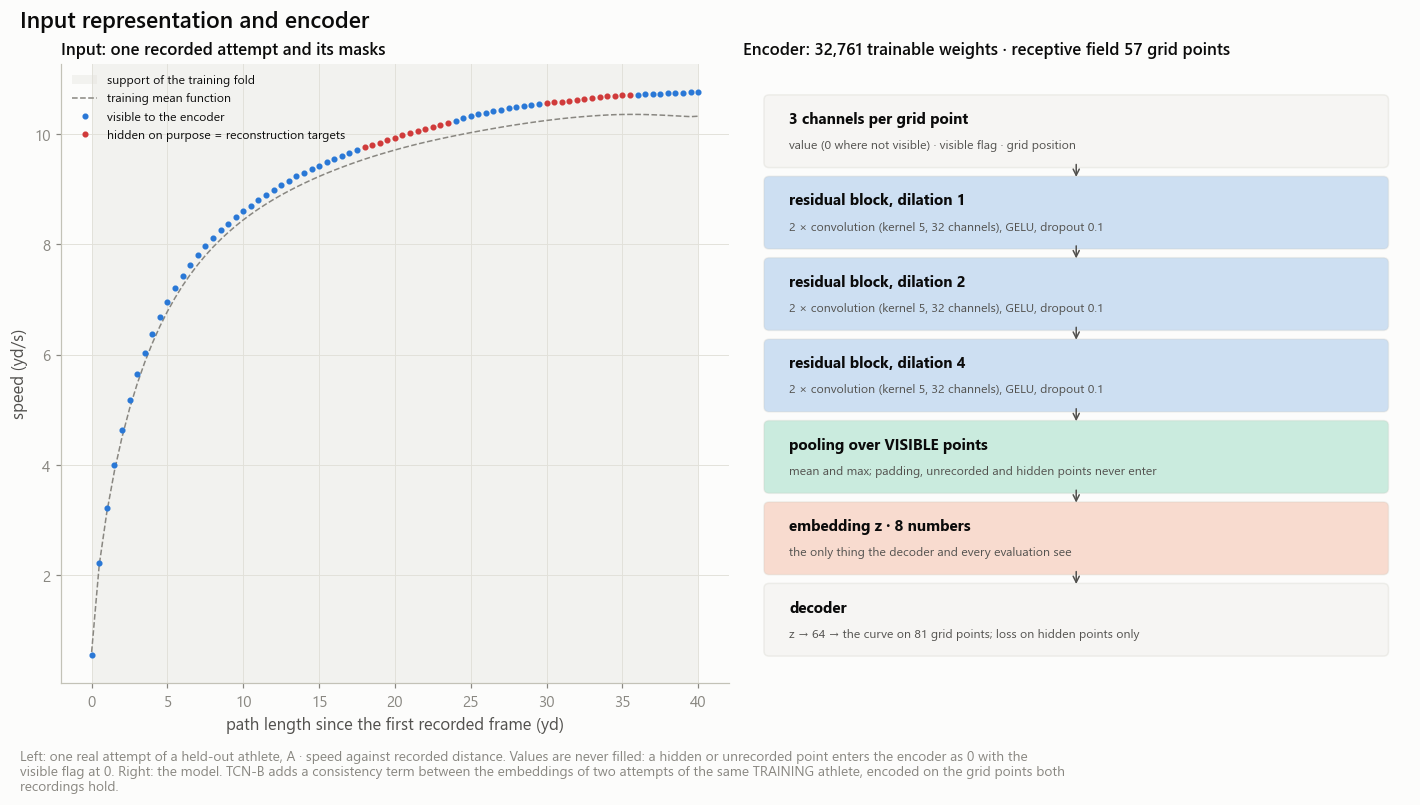

In [10]:
size_rows = []
for name in REPRESENTATIONS:
    cs = curves[name]
    n_params = tcn.count_parameters(tcn.CurveTCN(tcfg_a, cs.grid.size))
    pre = fold_preprocessing.filter(pl.col('representation') == name)
    train_curves = int(np.isin(cs.nfl_ids, amd.fold_athletes(splits, REPEATS[0], 0)[0]).sum())
    values = train_curves * int(pre['support_points'].min())
    size_rows.append({'representation': name, 'grid_points': int(cs.grid.size), 'support_points_min': int(pre['support_points'].min()),
                      'receptive_field_points': tcfg_a.receptive_field, 'trainable_parameters': n_params,
                      'training_curves_fold_0': train_curves, 'training_values_fold_0': values,
                      'values_per_parameter': values / n_params, 'fold_models_per_objective': len(supports) // len(REPRESENTATIONS),
                      'max_weight_updates_per_model': tcfg_a.max_epochs * int(np.ceil(pre['train_athletes'].max() / tcfg_a.batch_athletes))})
display(pl.DataFrame(size_rows))

# One real held-out attempt (median coverage of the support) to show the input and its masks.
cs = curves[PRIMARY]
train0, test0 = amd.fold_athletes(splits, REPEATS[0], 0)
norm0 = tcn.CurveNormalizer.fit(cs, train0, tcfg_a.min_coverage, tcfg_a.min_observed_fraction)
held0 = np.flatnonzero(np.isin(cs.nfl_ids, test0))
frac0 = norm0.fraction(norm0.observed(cs.Y[held0]))
pick = int(held0[np.argsort(frac0, kind='stable')[frac0.size // 2]])
example = {'grid': cs.grid, 'y': cs.Y[pick],
           'hidden': rv.evaluation_mask(cs.seq_ids[pick:pick + 1].astype(str), norm0.observed(cs.Y[pick:pick + 1]), controls.seed)[0]}
n_params_primary = tcn.count_parameters(tcn.CurveTCN(tcfg_a, cs.grid.size))
store.show(tf.plot_architecture(tcfg_a, norm0, example, n_params_primary, PRIMARY), 'AM03_01_architecture_and_input',
           publication=True, source='sequence_frames, split_registry', n='1 held-out attempt (illustration)',
           note='the attempt is the held-out sequence of outer fold 0 with the median coverage of the support')

## 8 · TCN-A training — masked reconstruction

Loss: mean squared error on the recorded points hidden on purpose, in normalised units. About 30 % of an attempt's recorded points are hidden in two contiguous runs; 35 % of the runs touch the first or last recorded point, which reproduces a shorter recording. Input noise at the measured noise level; the target is the clean recorded value.

One model per outer fold and per input: 5 folds × 3 inputs. Rerunning the cell restores the tables and reloads the checkpoints when nothing changed.

In [11]:
MODELS = {}     # (method, split repeat, outer fold) → fitted fold model; filled by training or from checkpoints
plan_a = tcn.tcn_plan(tcfg_a, None, REPRESENTATIONS, K)
out_a = tcn.run_stage(store, 'TCN_A', 'tcn_a', curves, splits, plan_a, REPEATS, ecfg, controls.seed, device, supports,
                      BASE_PARAMS, STAGE_FILES, MODELS)


def fold_fit_summary(fold_fits):
    return fold_fits.group_by('method').agg(
        pl.len().alias('fold_models'), pl.col('n_parameters').first(), pl.col('n_fit_athletes').min().alias('fit_athletes_min'),
        pl.col('n_dev_athletes').min().alias('dev_athletes_min'), pl.col('n_heldout_embedded').sum().alias('heldout_attempts_embedded'),
        (pl.col('n_heldout_sequences') - pl.col('n_heldout_embedded')).sum().alias('heldout_attempts_not_embedded'),
        pl.col('best_epoch').min().alias('best_epoch_min'), pl.col('best_epoch').max().alias('best_epoch_max'),
        pl.col('stopped_early').sum().alias('folds_stopped_early'), pl.col('train_seconds').sum().alias('train_seconds_total'),
        pl.col('device').first()).sort('method')


display(Markdown('**TCN-A fold models** (unit: fold model)'))
display(fold_fit_summary(out_a[tcn.FOLDS.name]))
display(out_a[tcn.FOLDS.name].select('method', 'outer_fold', 'n_fit_sequences', 'n_dev_sequences', 'n_support', 'n_eval_support',
                                      'scale', 'noise_sd', 'epochs_run', 'best_epoch', 'best_dev_loss', 'train_seconds'))

23:00:22 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:TCN_A] computing (never run)
23:00:56 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f0: 109 epochs (best 84), 33.9 s, 158 held-out attempts embedded
23:01:18 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f1: 72 epochs (best 47), 21.3 s, 162 held-out attempts embedded
23:02:18 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f2: 200 epochs (best 198), 60.5 s, 163 held-out attempts embedded
23:03:23 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f3: 200 epochs (best 184), 64.4 s, 157 held-out attempts embedded
23:03:54 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A r0_f4: 97 epochs (best 72), 30.4 s, 153 held-out attempts embedded
23:04:28 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] 

**TCN-A fold models** (unit: fold model)

method,fold_models,n_parameters,fit_athletes_min,dev_athletes_min,heldout_attempts_embedded,heldout_attempts_not_embedded,best_epoch_min,best_epoch_max,folds_stopped_early,train_seconds_total,device
str,u32,i64,i64,i64,i64,i64,i64,i64,u32,f64,str
"""TCNA_A""",5,32761,245,80,793,0,47,198,3,210.5232,"""cpu"""
"""TCNA_B""",5,30291,245,80,793,0,91,138,5,171.624318,"""cpu"""
"""TCNA_C""",5,31461,245,80,793,0,68,157,5,177.305719,"""cpu"""


method,outer_fold,n_fit_sequences,n_dev_sequences,n_support,n_eval_support,scale,noise_sd,epochs_run,best_epoch,best_dev_loss,train_seconds
str,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64
"""TCNA_A""",0,474,161,81,81,0.641064,0.002118,109,84,0.0424,33.877705
"""TCNA_A""",1,475,156,81,81,0.631639,0.00212,72,47,0.031899,21.334342
"""TCNA_A""",2,465,165,81,81,0.63099,0.002124,200,198,0.01821,60.454906
"""TCNA_A""",3,482,154,81,81,0.625964,0.002134,200,184,0.022359,64.446063
"""TCNA_A""",4,488,152,81,81,0.638031,0.002123,97,72,0.032426,30.410184
"""TCNA_B""",0,474,161,29,29,0.857396,0.038731,151,126,0.090926,33.682625
"""TCNA_B""",1,475,156,30,30,0.846777,0.04017,116,91,0.108384,25.678031
"""TCNA_B""",2,465,165,30,30,0.861032,0.039812,160,135,0.08763,45.210276
"""TCNA_B""",3,482,154,30,30,0.851944,0.038798,163,138,0.11279,39.725262


## 9 · TCN-A evaluation — reconstruction against the exact FPCA benchmark

Two reconstruction tasks, both on held-out athletes, in physical units, on the grid points shared by the fold's FPCA fit and the fold's encoder:

- **all recorded points visible**: FPCA computes its K scores from all points and reconstructs them; the encoder embeds all points and decodes. This is the error notebook 02 reports;
- **hidden points**: the same fixed mask for every method (seeded by the sequence identifier). FPCA predicts its scores from the visible points; the encoder embeds the visible points.

A lower error here says the bottleneck keeps more of the curve. It does not say the extra detail belongs to the athlete; sections 13 to 15 test that.

**Held-out reconstruction, TCN-A against FPCA** (unit: athlete; difference = method − FPCA of the same input)

method,reference,value_unit,n_athletes,n_sequences,rmse,rmse_lower,rmse_upper,fve,rmse_masked,rmse_diff,rmse_diff_lower,rmse_diff_upper,rmse_masked_diff,rmse_masked_diff_lower,rmse_masked_diff_upper
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""""","""yd/s""",418,793,0.100867,0.094802,0.107734,0.974672,0.169396,null,null,null,null,null,null
"""FPCA_B_K5""","""""","""yd/s²""",418,793,0.162087,0.156594,0.167487,0.964133,0.336494,null,null,null,null,null,null
"""FPCA_C_K2""","""""","""yd/s""",418,793,0.152378,0.130896,0.176239,0.962225,0.234161,null,null,null,null,null,null
"""TCNA_A""","""FPCA_A_K2""","""yd/s""",418,793,0.207061,0.196747,0.217943,0.893268,0.113562,0.106194,0.097454,0.115324,-0.055834,-0.068243,-0.041981
"""TCNA_B""","""FPCA_B_K5""","""yd/s²""",418,793,0.346828,0.326797,0.36881,0.835779,0.287646,0.184741,0.166892,0.203535,-0.048848,-0.068285,-0.029501
"""TCNA_C""","""FPCA_C_K2""","""yd/s""",418,793,0.294386,0.230372,0.38226,0.859006,0.209222,0.142008,0.082567,0.224739,-0.024939,-0.096668,0.053863


**Collapse check of the TCN-A embeddings** (unit: fold model, held-out attempts)

method,repeat,outer_fold,n_sequences,embedding_dim,dim_sd_min,dim_sd_max,effective_rank,rank_share,participation_ratio,top_eigen_share,near_identical_share,median_distance,collapsed
str,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""TCNA_A""",0,0,158,8,0.345608,1.205315,1.644247,0.205531,1.308941,0.868342,0.0,2.308403,true
"""TCNA_A""",0,1,162,8,0.141497,1.389027,1.510318,0.18879,1.228996,0.899065,0.0,2.554113,true
"""TCNA_A""",0,2,163,8,0.254008,1.319414,1.286319,0.16079,1.106676,0.949972,0.0,2.282545,true
"""TCNA_A""",0,3,157,8,0.097625,1.972238,1.39547,0.174434,1.17905,0.918382,0.0,2.583525,true
"""TCNA_A""",0,4,153,8,0.251858,1.684586,1.586911,0.198364,1.311493,0.865117,0.0,2.57907,true
"""TCNA_B""",0,0,158,8,0.336709,1.382904,2.03457,0.254321,1.56336,0.785287,0.0,2.163458,false
"""TCNA_B""",0,1,162,8,0.29804,1.342812,1.778163,0.22227,1.402066,0.834604,0.0,2.39658,true
"""TCNA_B""",0,2,163,8,0.355933,1.215664,2.050284,0.256285,1.616602,0.763185,0.0,2.416201,false
"""TCNA_B""",0,3,157,8,0.265251,1.247375,1.987943,0.248493,1.585181,0.770631,0.0,2.751799,true


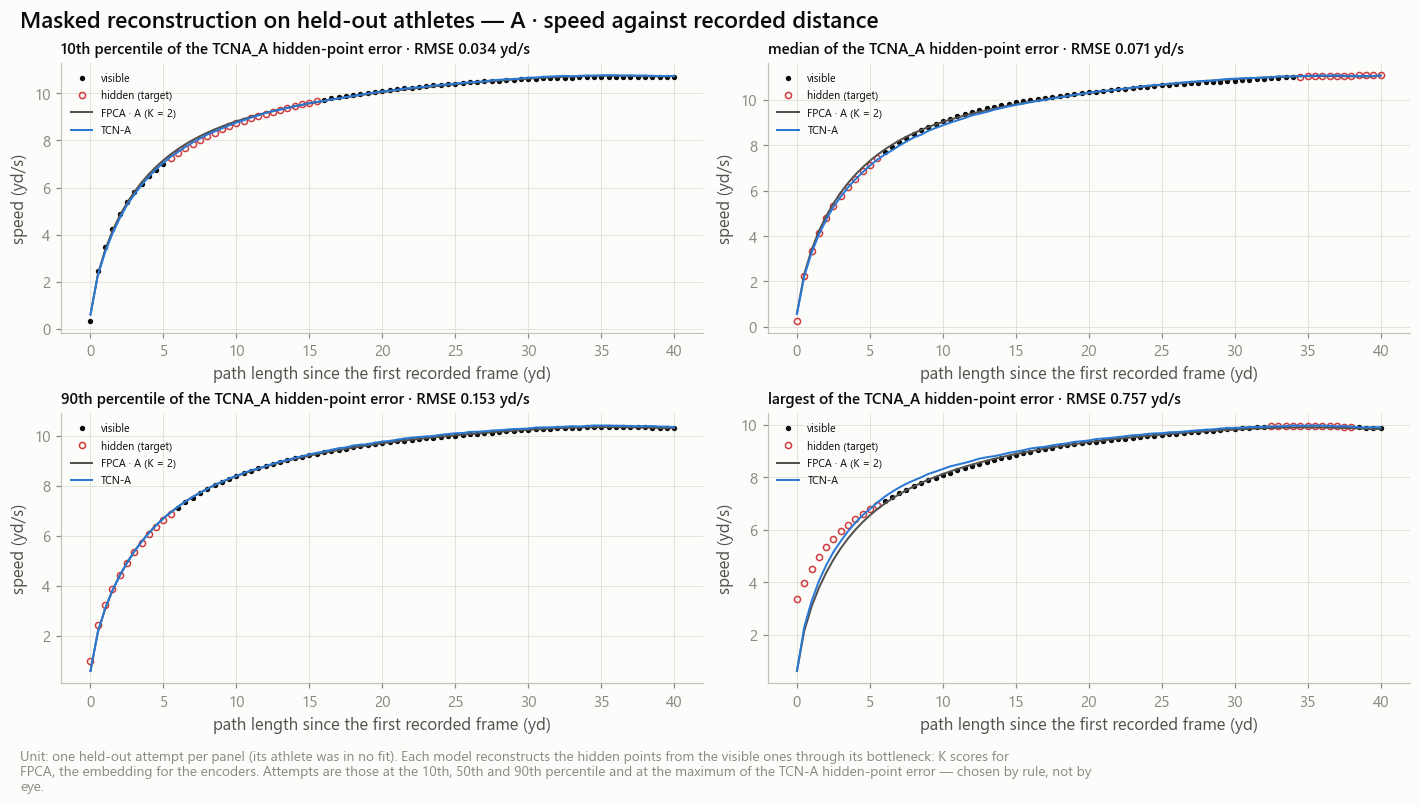

In [12]:
methods_a = tcn.methods_table([*fpca_specs, *[s for s, _ in plan_a]], out_a[tcn.FOLDS.name], fpca_models)
recon_seq_a = pl.concat([fpca_ref[rv.RECON_SEQ.name], out_a[rv.RECON_SEQ.name]])
recon_a = rv.reconstruction_table(recon_seq_a, methods_a, ecfg, controls.seed)
display(Markdown('**Held-out reconstruction, TCN-A against FPCA** (unit: athlete; difference = method − FPCA of the same input)'))
display(recon_a.select('method', 'reference', 'value_unit', 'n_athletes', 'n_sequences', 'rmse', 'rmse_lower', 'rmse_upper', 'fve',
                       'rmse_masked', 'rmse_diff', 'rmse_diff_lower', 'rmse_diff_upper', 'rmse_masked_diff',
                       'rmse_masked_diff_lower', 'rmse_masked_diff_upper'))
display(Markdown('**Collapse check of the TCN-A embeddings** (unit: fold model, held-out attempts)'))
display(rv.collapse_tables(out_a[rv.EMBEDDINGS.name], ecfg)[rv.COLLAPSE.name])


def show_masked_examples(tcn_methods, figure_name):
    examples = tcn.masked_examples(curves[PRIMARY], recon_seq_a, 'TCNA_A', tcn_methods, MODELS, fpca_specs[REPRESENTATIONS.index(PRIMARY)],
                                   fpca_models[PRIMARY], supports, controls.seed, device)
    if not any(len(e['recon']) > 1 for e in examples):
        display(Markdown('_Masked-reconstruction examples need the fold models: none is in memory or on disk for this '
                         'configuration (SAVE_MODELS was off). Set FORCE_REBUILD = True to retrain._'))
        return
    store.show(tf.plot_masked_examples(examples, PRIMARY), figure_name, publication=True,
               source='sequence_frames, fold models', n=f'{len(examples)} held-out attempts (rule-selected)')


show_masked_examples({'TCN-A': (tcn.RECON, 'TCNA_A')}, 'AM03_02_masked_reconstruction_examples_tcn_a')

## 10 · TCN-B training — reconstruction and attempt consistency

$L = L_{\text{reconstruction}} + \lambda \, L_{\text{consistency}}$

A positive pair is two attempts of the same **training** athlete. Both are encoded on the grid points the two recordings share, so the comparison never sets a region recorded in one attempt against nothing in the other. Pairs sharing less than half of the support are not used.

Two formulations are compared:

| Kind | Loss | Protection against collapse |
|---|---|---|
| `vicreg` | squared distance between the two embeddings + a hinge keeping the spread of every dimension + a decorrelation term | explicit |
| `mse` | squared distance divided by the batch variance | none beyond the reconstruction term |

Neither uses negative pairs: two different athletes are never assumed dissimilar, because similar athletes exist. No position label enters the loss, and the reconstruction term keeps the whole curve in the embedding, so agreeing on top speed alone does not minimise it.

### Choosing the kind and the weight on design athletes only

The first cell ranks the candidates **inside the design athletes** (input A): for each inner fold, the encoder is trained on the other design athletes and scored on that fold by the within-position repeat-attempt AUC. Confirm athletes are in no model of this cell. Rule fixed in advance: among candidates that did not collapse, the largest AUC; ties within 0.005 go to the smallest weight. The row `none` is TCN-A, shown for reference.

The design subset is small, so this ranking is noisy. It is a bounded sensitivity analysis, not an optimisation, and the result is used once.

In [13]:
meta = fe.Meta(windows, athletes)
DESIGN_PARAMS = {**BASE_PARAMS, 'base': tcfg_a.params(), 'grid': [list(g) for g in CONSISTENCY_GRID], 'input': PRIMARY,
                 'default': list(CONSISTENCY_DEFAULT), 'top_k': ecfg.top_k, 'collapse': [ecfg.collapse_rank_share,
                                                                                        ecfg.collapse_identical_share]}


def build_design():
    raw = tcn.design_sweep(curves[PRIMARY], splits, meta, tcfg_a, CONSISTENCY_GRID, ecfg, controls.seed, device)
    return {tcn.DESIGN.name: tcn.select_consistency(raw, CONSISTENCY_DEFAULT)[0]}


design = store.build('TCN_DESIGN', [tcn.DESIGN], build_design, params=DESIGN_PARAMS,
                     files=[*STAGE_FILES, store.parquet(ck.WINDOWS)])[tcn.DESIGN.name]
design, CONSISTENCY_KIND, CONSISTENCY_WEIGHT, CONSISTENCY_REASON = tcn.select_consistency(design, CONSISTENCY_DEFAULT)
display(Markdown(f'**Consistency term compared on the {n_design} design athletes** (unit: design athlete with two attempts, '
                 'scored by an encoder that did not see him)'))
display(design)
display(Markdown(f'**Selected: `{CONSISTENCY_KIND}`, λ = {CONSISTENCY_WEIGHT:g}.** {CONSISTENCY_REASON}. '
                 'The same term is applied to inputs B and C without further tuning.'))

23:09:50 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:TCN_DESIGN] computing (never run)
23:20:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:TCN_DESIGN] tcn_design_sweep: 7 rows → warehouse/gold/advanced_movement/tcn_design_sweep.parquet


**Consistency term compared on the 125 design athletes** (unit: design athlete with two attempts, scored by an encoder that did not see him)

consistency,consistency_weight,n_folds,n_athletes_repeat,auc,auc_fold_min,auc_fold_max,top1,rmse_masked,rank_share_min,near_identical_max,collapsed,selected
str,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,bool,bool
"""none""",0.0,4,108,0.848021,0.81125,0.880357,0.574074,0.147345,0.137233,0.0,true,false
"""vicreg""",0.1,4,108,0.876185,0.841398,0.908929,0.611111,0.150594,0.144326,0.0,true,false
"""vicreg""",0.3,4,108,0.87101,0.8475,0.883929,0.615741,0.157899,0.181751,0.0,true,true
"""vicreg""",1.0,4,108,0.854552,0.840517,0.88869,0.583333,0.256874,0.135241,0.0,true,false
"""mse""",0.1,4,108,0.814175,0.760753,0.868021,0.532407,0.148817,0.137238,0.0,true,false
"""mse""",0.3,4,108,0.870321,0.840726,0.90119,0.601852,0.166014,0.126192,0.001057,true,false
"""mse""",1.0,4,108,0.835373,0.703715,0.895238,0.592593,0.380946,0.126566,0.0,true,false


**Selected: `vicreg`, λ = 0.3.** no candidate could be ranked on the design athletes (too few pairs or every candidate collapsed): pre-declared default kept. The same term is applied to inputs B and C without further tuning.

In [14]:
tcfg_b = replace(tcfg_a, objective=tcn.CONSISTENCY, consistency=CONSISTENCY_KIND, consistency_weight=CONSISTENCY_WEIGHT)
plan_b = tcn.tcn_plan(None, tcfg_b, REPRESENTATIONS, K)
out_b = tcn.run_stage(store, 'TCN_B', 'tcn_b', curves, splits, plan_b, REPEATS, ecfg, controls.seed, device, supports,
                      BASE_PARAMS, STAGE_FILES, MODELS)
display(Markdown('**TCN-B fold models** (unit: fold model)'))
display(fold_fit_summary(out_b[tcn.FOLDS.name]))

# Declared sensitivity: 16-dimensional embeddings on input A, both objectives. Reported, never selected.
plan_16 = (tcn.tcn_plan(replace(tcfg_a, embedding_dim=16), replace(tcfg_b, embedding_dim=16), [PRIMARY], K, suffix='_E16', primary=False)
           if RUN_SENSITIVITY_16 else [])
out_16 = (tcn.run_stage(store, 'TCN_E16', 'tcn_e16', curves, splits, plan_16, REPEATS, ecfg, controls.seed, device, supports,
                        BASE_PARAMS, STAGE_FILES, MODELS) if plan_16 else None)
if out_16 is not None:
    display(Markdown('**16-dimensional sensitivity models** (unit: fold model)'))
    display(fold_fit_summary(out_16[tcn.FOLDS.name]))

23:20:30 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:TCN_B] computing (never run)


23:21:42 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_A r0_f0: 110 epochs (best 85), 71.1 s, 158 held-out attempts embedded
23:22:19 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_A r0_f1: 60 epochs (best 35), 37.3 s, 162 held-out attempts embedded
23:24:24 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_A r0_f2: 199 epochs (best 174), 124.3 s, 163 held-out attempts embedded
23:25:33 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_A r0_f3: 112 epochs (best 87), 69.0 s, 157 held-out attempts embedded
23:28:29 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_A r0_f4: 200 epochs (best 186), 175.2 s, 153 held-out attempts embedded
23:29:03 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNB_B r0_f0: 75 epochs (best 50), 34.2 s, 158 held-out attempts embedded
23:30:28 | INFO    | nflbdb.research.a

**TCN-B fold models** (unit: fold model)

method,fold_models,n_parameters,fit_athletes_min,dev_athletes_min,heldout_attempts_embedded,heldout_attempts_not_embedded,best_epoch_min,best_epoch_max,folds_stopped_early,train_seconds_total,device
str,u32,i64,i64,i64,i64,i64,i64,i64,u32,f64,str
"""TCNB_A""",5,32761,245,80,793,0,35,186,4,476.989689,"""cpu"""
"""TCNB_B""",5,30291,245,80,793,0,36,169,5,259.652004,"""cpu"""
"""TCNB_C""",5,31461,245,80,793,0,91,152,5,372.948817,"""cpu"""


23:39:04 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:TCN_E16] computing (never run)
23:39:50 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A_E16 r0_f0: 166 epochs (best 141), 45.8 s, 158 held-out attempts embedded
23:40:22 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A_E16 r0_f1: 114 epochs (best 89), 32.0 s, 162 held-out attempts embedded
23:41:08 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A_E16 r0_f2: 159 epochs (best 134), 46.4 s, 163 held-out attempts embedded
23:41:40 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A_E16 r0_f3: 100 epochs (best 75), 31.7 s, 157 held-out attempts embedded
23:42:21 | INFO    | nflbdb.research.advanced_movement.tcn | [advanced_movement:TCN] TCNA_A_E16 r0_f4: 126 epochs (best 101), 40.7 s, 153 held-out attempts embedded
23:44:17 | INFO    | nflbdb.research.advanced_movement.tcn |

**16-dimensional sensitivity models** (unit: fold model)

method,fold_models,n_parameters,fit_athletes_min,dev_athletes_min,heldout_attempts_embedded,heldout_attempts_not_embedded,best_epoch_min,best_epoch_max,folds_stopped_early,train_seconds_total,device
str,u32,i64,i64,i64,i64,i64,i64,i64,u32,f64,str
"""TCNA_A_E16""",5,33793,245,80,793,0,75,141,5,196.627886,"""cpu"""
"""TCNB_A_E16""",5,33793,245,80,793,0,79,175,4,423.095506,"""cpu"""


## 11 · TCN-B evaluation — learning curves and reconstruction

The consistency term is expected to cost some reconstruction accuracy: it asks the embedding to ignore what differs between two attempts of one athlete. How much it costs is shown here; whether it buys repeatability that the stopwatch does not explain is the subject of sections 13 and 14.

This cell also assembles every method into one set of embeddings and checks that all methods of an input are scored on the same held-out attempts.

**Methods** (unit: method)

method,family,objective,representation,embedding_dim,label,reference,primary,n_parameters,train_seconds,value_unit
str,str,str,str,i64,str,str,bool,i64,f64,str
"""FPCA_A_K2""","""fpca""","""fpca""","""A_speed_by_distance""",2,"""FPCA · A (K = 2)""","""""",true,48,null,"""yd/s"""
"""FPCA_B_K5""","""fpca""","""fpca""","""B_accel_by_speed""",5,"""FPCA · B (K = 5)""","""""",true,60,null,"""yd/s²"""
"""FPCA_C_K2""","""fpca""","""fpca""","""C_speed_by_time""",2,"""FPCA · C (K = 2)""","""""",true,48,null,"""yd/s"""
"""TCNA_A""","""tcn""","""reconstruction""","""A_speed_by_distance""",8,"""TCN-A · A (8-d)""","""FPCA_A_K2""",true,32761,210.5232,"""yd/s"""
"""TCNA_B""","""tcn""","""reconstruction""","""B_accel_by_speed""",8,"""TCN-A · B (8-d)""","""FPCA_B_K5""",true,30291,171.624318,"""yd/s²"""
"""TCNA_C""","""tcn""","""reconstruction""","""C_speed_by_time""",8,"""TCN-A · C (8-d)""","""FPCA_C_K2""",true,31461,177.305719,"""yd/s"""
"""TCNB_A""","""tcn""","""reconstruction+consistency""","""A_speed_by_distance""",8,"""TCN-B · A (8-d)""","""FPCA_A_K2""",true,32761,476.989689,"""yd/s"""
"""TCNB_B""","""tcn""","""reconstruction+consistency""","""B_accel_by_speed""",8,"""TCN-B · B (8-d)""","""FPCA_B_K5""",true,30291,259.652004,"""yd/s²"""
"""TCNB_C""","""tcn""","""reconstruction+consistency""","""C_speed_by_time""",8,"""TCN-B · C (8-d)""","""FPCA_C_K2""",true,31461,372.948817,"""yd/s"""


**Evaluation cohort** — held-out attempts embedded by each method. Restricting every input to the attempts all its methods embed removed 0 embedding rows (0 = the cohorts already coincide).

method,n_sequences,n_athletes,n_sequences_common_to_all
str,u32,u32,i32
"""FPCA_A_K2""",793,418,793
"""TCNA_A""",793,418,793
"""TCNA_A_E16""",793,418,793
"""TCNB_A""",793,418,793
"""TCNB_A_E16""",793,418,793
"""FPCA_B_K5""",793,418,793
"""TCNA_B""",793,418,793
"""TCNB_B""",793,418,793
"""FPCA_C_K2""",793,418,793


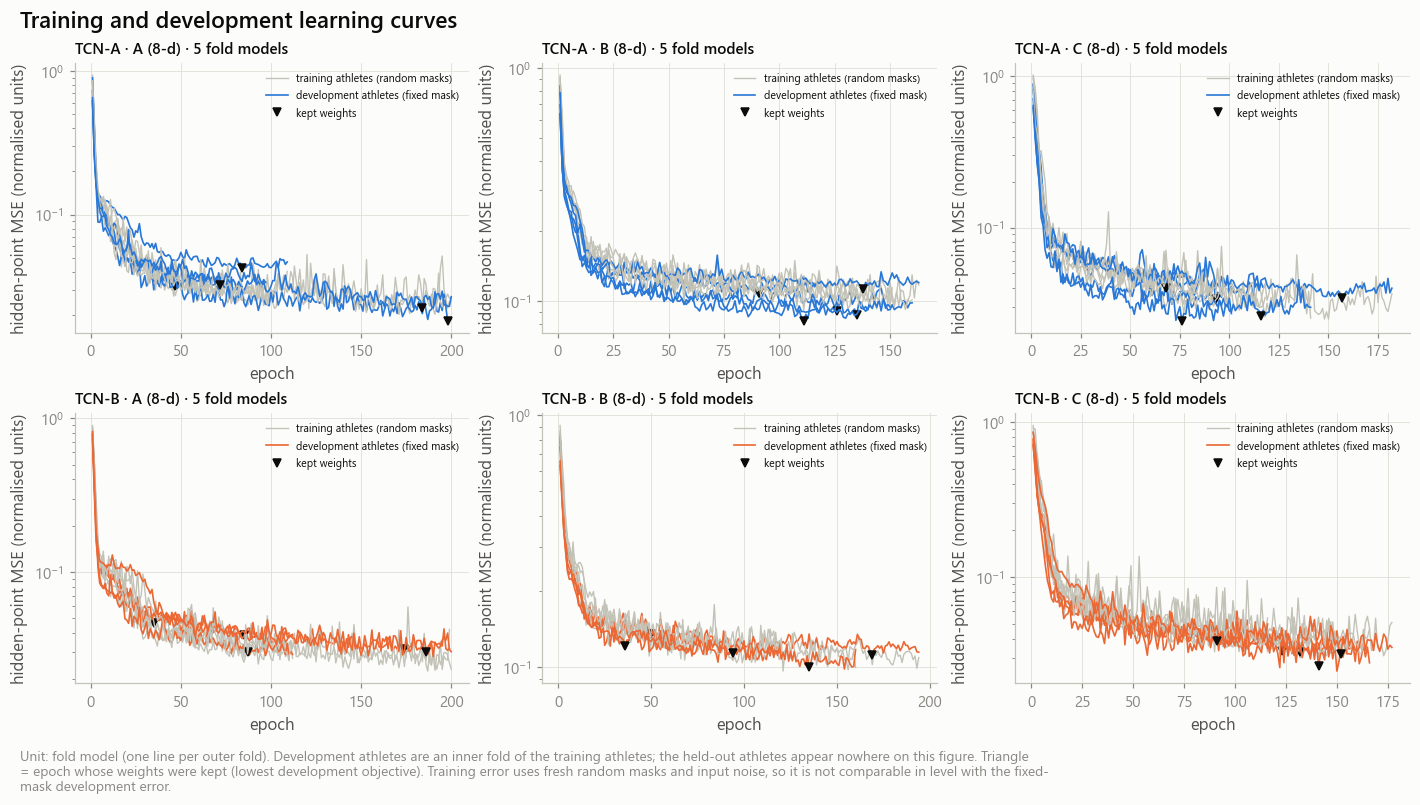

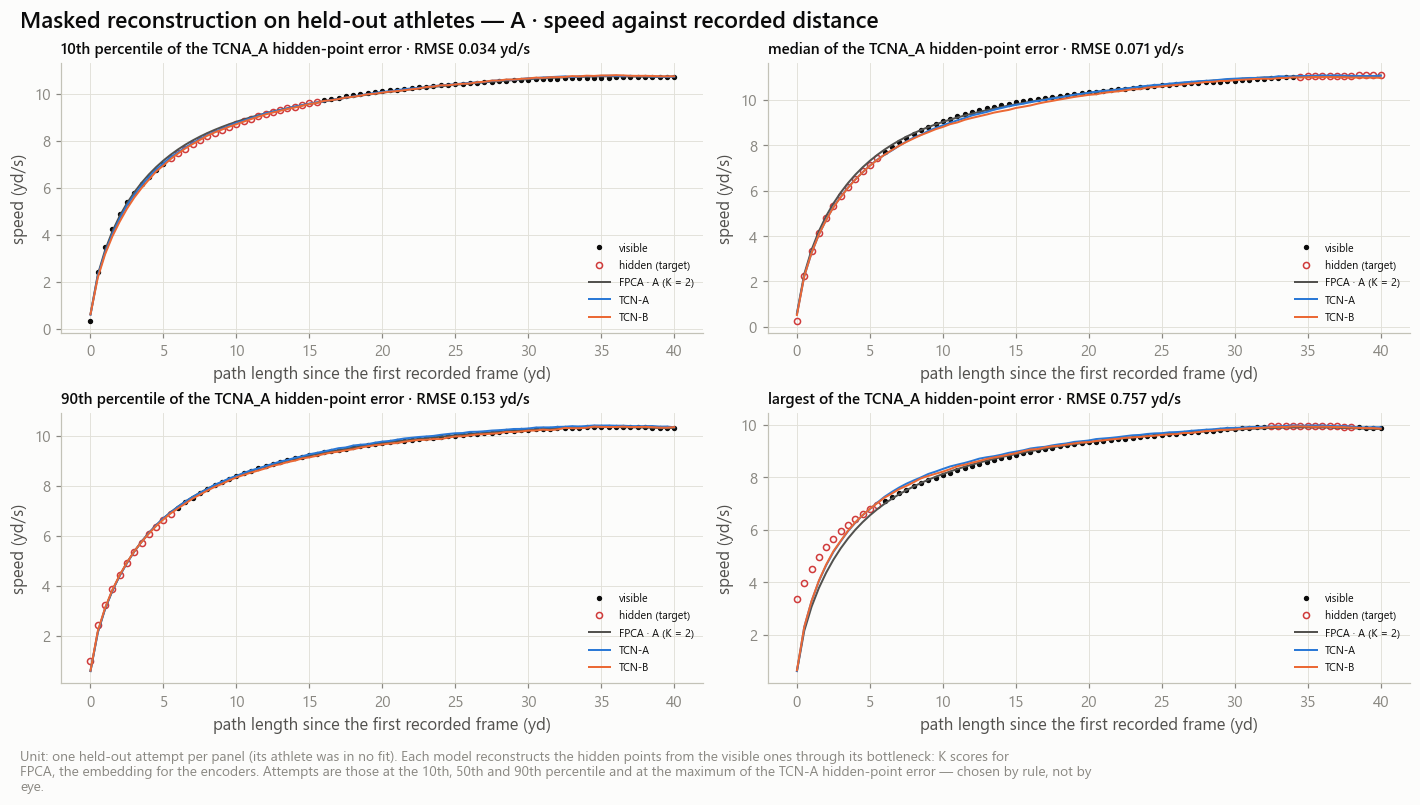

In [15]:
stages = [out_a, out_b] + ([out_16] if out_16 is not None else [])
history = pl.concat([s[tcn.HISTORY.name] for s in stages])
fold_fits = pl.concat([s[tcn.FOLDS.name] for s in stages])
plan_all = [*plan_a, *plan_b, *plan_16]
methods = tcn.methods_table([*fpca_specs, *[s for s, _ in plan_all]], fold_fits, fpca_models)
emb = pl.concat([fpca_ref[rv.EMBEDDINGS.name], *[s[rv.EMBEDDINGS.name] for s in stages]])
recon_seq = pl.concat([fpca_ref[rv.RECON_SEQ.name], *[s[rv.RECON_SEQ.name] for s in stages]])

# Fairness: methods of one input must be scored on the same held-out attempts.
groups = [methods.filter(pl.col('representation') == name)['method'].to_list() for name in REPRESENTATIONS]
n_before = emb.height
emb = rv.restrict_to_common(emb, groups)
display(Markdown('**Methods** (unit: method)'))
display(methods)
display(Markdown(f'**Evaluation cohort** — held-out attempts embedded by each method. Restricting every input to the attempts all '
                 f'its methods embed removed {n_before - emb.height} embedding rows (0 = the cohorts already coincide).'))
display(pl.concat([rv.cohort_match(emb.filter(pl.col('method').is_in(g))) for g in groups]))

store.show(tf.plot_learning_curves(history, methods), 'AM03_03_learning_curves', {'history': history}, publication=False,
           source='tcn_a_training_history, tcn_b_training_history', n=f'{fold_fits.filter(pl.col("method").is_in(methods.filter(pl.col("primary"))["method"].to_list())).height} fold models')
show_masked_examples({'TCN-A': (tcn.RECON, 'TCNA_A'), 'TCN-B': (tcn.CONSISTENCY, 'TCNB_A')}, 'AM03_02_masked_reconstruction_examples')

### Evaluation tables

The next cell computes every evaluation table once, for all methods, from the held-out embeddings (stage `REPR_EVAL`), then the summary and the rule-based reading (stage `REPR_GATE`). The sections after it only display and plot.

23:49:37 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:REPR_EVAL] computing (never run)


23:50:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_EVAL] repr_methods: 11 rows → warehouse/gold/advanced_movement/repr_methods.parquet
23:50:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_EVAL] repr_athlete_embeddings: 37,202 rows → warehouse/gold/advanced_movement/repr_athlete_embeddings.parquet
23:50:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_EVAL] repr_pair_statistics: 49,500 rows → warehouse/gold/advanced_movement/repr_pair_statistics.parquet
23:50:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_EVAL] repr_repeatability: 572 rows → warehouse/gold/advanced_movement/repr_repeatability.parquet
23:50:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_EVAL] repr_paired_comparisons: 288 rows → warehouse/gold/advanced_movement/repr_paired_comparisons.parquet
23:50:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REPR_

**Held-out reconstruction, all methods** (unit: athlete; difference = method − FPCA of the same input)

method,reference,value_unit,n_athletes,rmse,rmse_lower,rmse_upper,fve,rmse_masked,rmse_masked_lower,rmse_masked_upper,rmse_diff,rmse_diff_lower,rmse_diff_upper,rmse_masked_diff,rmse_masked_diff_lower,rmse_masked_diff_upper
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""""","""yd/s""",418,0.100867,0.094802,0.107734,0.974672,0.169396,0.149807,0.190996,null,null,null,null,null,null
"""FPCA_B_K5""","""""","""yd/s²""",418,0.162087,0.156594,0.167487,0.964133,0.336494,0.316473,0.358935,null,null,null,null,null,null
"""FPCA_C_K2""","""""","""yd/s""",418,0.152378,0.130896,0.176239,0.962225,0.234161,0.192277,0.276499,null,null,null,null,null,null
"""TCNA_A""","""FPCA_A_K2""","""yd/s""",418,0.207061,0.196747,0.217943,0.893268,0.113562,0.101412,0.1259,0.106194,0.097454,0.115324,-0.055834,-0.068243,-0.041981
"""TCNA_A_E16""","""FPCA_A_K2""","""yd/s""",418,0.204167,0.194587,0.214314,0.896231,0.110391,0.097831,0.125152,0.1033,0.094712,0.112124,-0.059005,-0.071846,-0.045648
"""TCNA_B""","""FPCA_B_K5""","""yd/s²""",418,0.346828,0.326797,0.36881,0.835779,0.287646,0.268679,0.308465,0.184741,0.166892,0.203535,-0.048848,-0.068285,-0.029501
"""TCNA_C""","""FPCA_C_K2""","""yd/s""",418,0.294386,0.230372,0.38226,0.859006,0.209222,0.1351,0.301072,0.142008,0.082567,0.224739,-0.024939,-0.096668,0.053863
"""TCNB_A""","""FPCA_A_K2""","""yd/s""",418,0.235611,0.220068,0.252383,0.861806,0.124663,0.110597,0.140365,0.134744,0.121986,0.147803,-0.044734,-0.058215,-0.029859
"""TCNB_A_E16""","""FPCA_A_K2""","""yd/s""",418,0.23486,0.219117,0.251598,0.862686,0.117533,0.104345,0.131764,0.133993,0.122152,0.146051,-0.051864,-0.063532,-0.041034


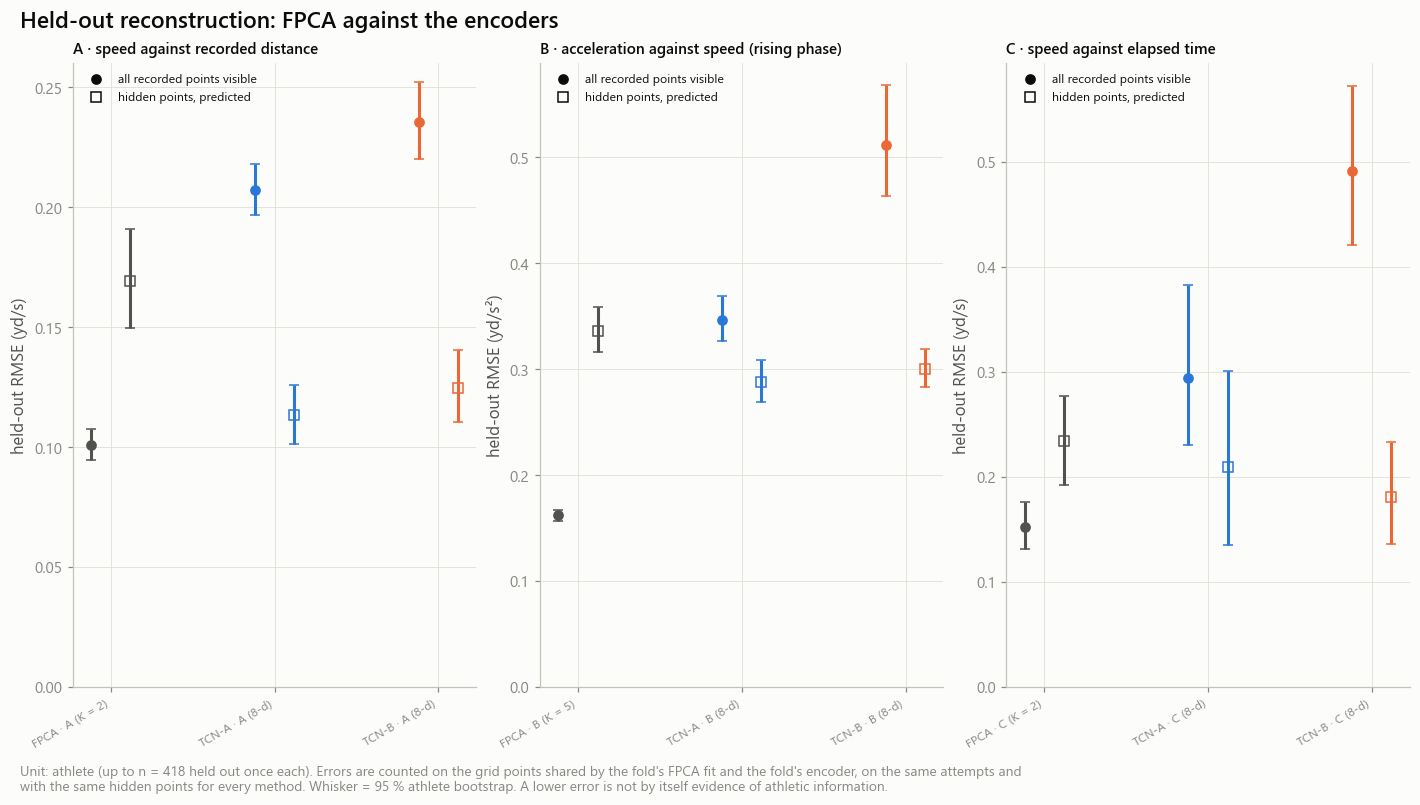

In [16]:
prefixes = ['fpca_ref', 'tcn_a', 'tcn_b'] + (['tcn_e16'] if out_16 is not None else [])
EVAL_FILES = [*[store.parquet(rv.named(rv.EMBEDDINGS, p)) for p in prefixes], store.parquet(ck.WINDOWS), store.parquet(amd.ATHLETES),
              store.parquet(amd.SPLITS)]
EVAL_PARAMS = {**BASE_PARAMS, 'eval': ecfg.params(), 'methods': methods['method'].to_list(),
               'plan': [{'method': s.method, **t.params()} for s, t in plan_all]}
ev = store.build('REPR_EVAL', [rv.METHODS, *rv.EVAL_CONTRACTS],
                 lambda: {rv.METHODS.name: methods,
                          **rv.evaluate(emb, recon_seq, methods, windows, athletes, splits, ecfg, controls.seed)},
                 params=EVAL_PARAMS, files=EVAL_FILES)
gated = store.build('REPR_GATE', list(rv.GATE_CONTRACTS), lambda: rv.gate(ev, methods, ecfg), params=EVAL_PARAMS, files=EVAL_FILES)
method_summary, verdict = gated[rv.SUMMARY.name], gated[rv.VERDICT.name]
recon = ev[rv.RECON.name]

display(Markdown('**Held-out reconstruction, all methods** (unit: athlete; difference = method − FPCA of the same input)'))
display(recon.select('method', 'reference', 'value_unit', 'n_athletes', 'rmse', 'rmse_lower', 'rmse_upper', 'fve', 'rmse_masked',
                     'rmse_masked_lower', 'rmse_masked_upper', 'rmse_diff', 'rmse_diff_lower', 'rmse_diff_upper',
                     'rmse_masked_diff', 'rmse_masked_diff_lower', 'rmse_masked_diff_upper'))
store.show(tf.plot_reconstruction(recon, methods), 'AM03_04_reconstruction_fpca_tcn_a_tcn_b', {'reconstruction': recon},
           publication=True, source='repr_reconstruction', n=f'{recon["n_athletes"].max()} athletes')

## 12 · Representation collapse diagnostics

An encoder trained to make two attempts agree can satisfy the objective by giving every athlete the same vector, or by using a single direction. Before any repeatability number is read, each fold model is checked on its held-out embeddings:

- **per-dimension spread** (smallest and largest standard deviation);
- **covariance spectrum** and **effective rank** (the exponential of the entropy of the normalised eigenvalues): how many directions the embedding really uses. An FPCA with K components cannot exceed K;
- **pairwise distances**: the median, and the share of attempt pairs closer than 1 % of it.

A model whose effective rank is below a quarter of its dimension, or with more than 5 % of nearly identical pairs, is flagged as collapsed. Both lines are heuristic. A collapsed method is reported as such and is not credited with repeatability.

**Collapse diagnostics by method** (unit: fold model; smallest / largest value over the fold models)

method,fold_models,embedding_dim,dim_sd_min,dim_sd_max,effective_rank_min,effective_rank_max,rank_share_min,top_eigen_share_max,near_identical_share_max,median_distance_min,fold_models_collapsed
str,u32,i64,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""FPCA_A_K2""",5,2,0.779863,4.076405,1.164937,1.287605,0.582469,0.964712,0.00046,3.77998,0
"""FPCA_B_K5""",5,5,0.212717,2.216918,1.720024,2.028717,0.344005,0.861931,0.0,2.236485,0
"""FPCA_C_K2""",5,2,0.666148,1.80397,1.51611,1.755468,0.758055,0.85375,0.000172,1.689491,0
"""TCNA_A""",5,8,0.097625,1.972238,1.286319,1.644247,0.16079,0.949972,0.0,2.282545,5
"""TCNA_A_E16""",5,16,0.137218,1.840855,1.383116,1.940577,0.086445,0.926789,0.0,2.446062,5
"""TCNA_B""",5,8,0.265251,1.382904,1.773011,2.050284,0.221626,0.834604,0.0,2.163458,3
"""TCNA_C""",5,8,0.128551,1.944778,1.835017,2.143156,0.229377,0.781391,0.0,2.213514,4
"""TCNB_A""",5,8,0.815763,1.053511,2.036288,2.935152,0.254536,0.619243,0.000077,3.307083,0
"""TCNB_A_E16""",5,16,0.780178,1.071532,3.092245,3.873062,0.193265,0.458379,0.0,5.270728,5


**Collapse monitor during training** (development athletes; effective rank / dimension at the kept epoch)

method,dev_rank_share_min,dev_rank_share_max
str,f64,f64
"""TCNA_A""",0.155966,0.1812
"""TCNA_A_E16""",0.082303,0.092768
"""TCNA_B""",0.215769,0.241609
"""TCNA_C""",0.217514,0.234719
"""TCNB_A""",0.246249,0.362762
"""TCNB_A_E16""",0.186713,0.225276
"""TCNB_B""",0.142381,0.270285
"""TCNB_C""",0.247579,0.33966


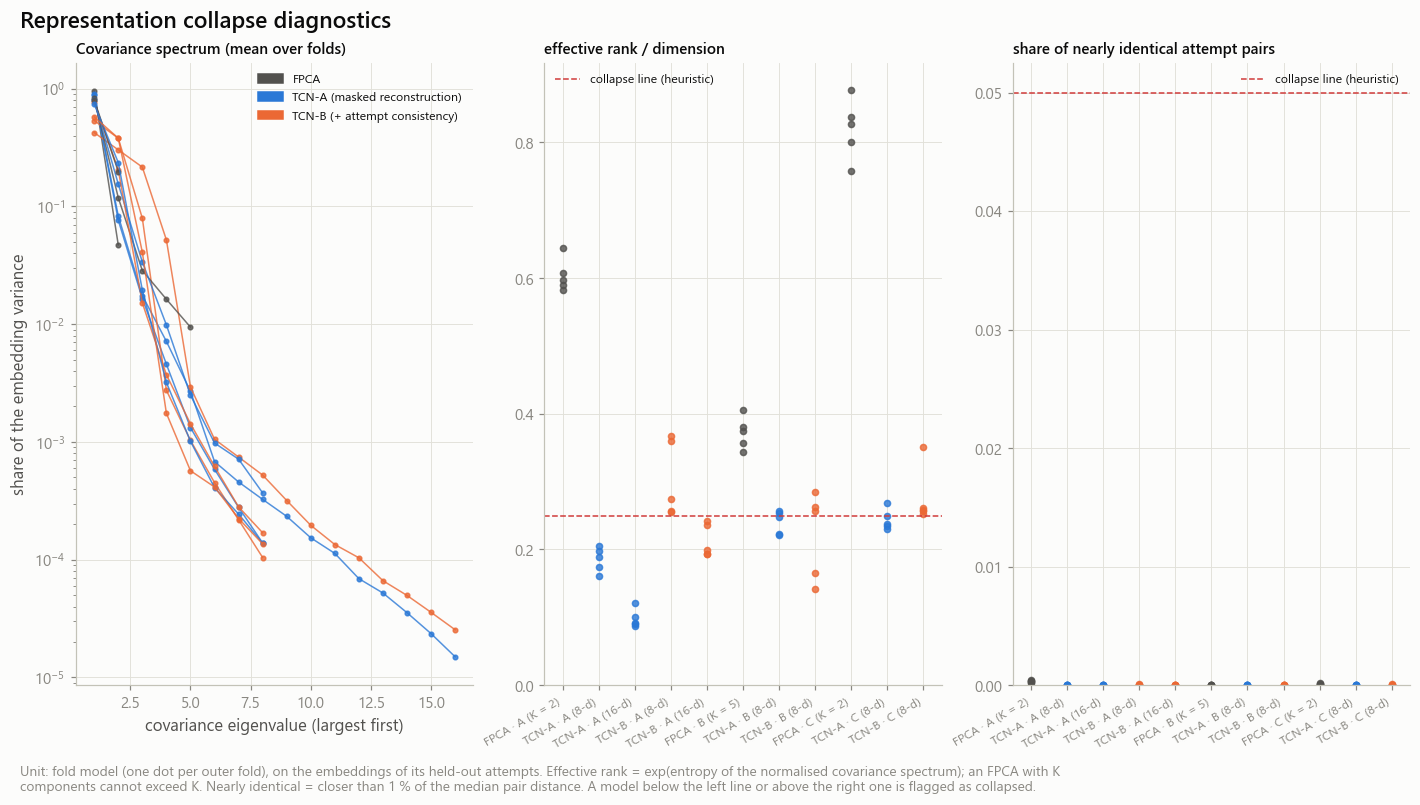

In [17]:
collapse, spectrum = ev[rv.COLLAPSE.name], ev[rv.SPECTRUM.name]
display(Markdown('**Collapse diagnostics by method** (unit: fold model; smallest / largest value over the fold models)'))
display(collapse.group_by('method').agg(
    pl.len().alias('fold_models'), pl.col('embedding_dim').first(), pl.col('dim_sd_min').min(), pl.col('dim_sd_max').max(),
    pl.col('effective_rank').min().alias('effective_rank_min'), pl.col('effective_rank').max().alias('effective_rank_max'),
    pl.col('rank_share').min().alias('rank_share_min'), pl.col('top_eigen_share').max().alias('top_eigen_share_max'),
    pl.col('near_identical_share').max().alias('near_identical_share_max'), pl.col('median_distance').min().alias('median_distance_min'),
    pl.col('collapsed').sum().alias('fold_models_collapsed')).sort('method'))
display(Markdown('**Collapse monitor during training** (development athletes; effective rank / dimension at the kept epoch)'))
display(history.filter(pl.col('is_best')).group_by('method').agg(pl.col('dev_rank_share').min().alias('dev_rank_share_min'),
                                                                 pl.col('dev_rank_share').max().alias('dev_rank_share_max')).sort('method'))
store.show(tf.plot_collapse(collapse, spectrum, methods, ecfg), 'AM03_07_collapse_diagnostics', {'collapse': collapse, 'spectrum': spectrum},
           source='repr_collapse, repr_covariance_spectrum', n=f'{collapse.height} fold models')

## 13 · Repeatability evaluation

The central measurement. For a held-out athlete with two embedded attempts:

- **query** = one attempt; **gallery** = the other attempt of every athlete of the same position held out in the same fold;
- **AUC** = share of the gallery that is farther from the query than the athlete's own other attempt (0.5 = chance, 1 = always nearest);
- **top-1 / top-5** = his own attempt is the nearest / among the five nearest; **MRR** = mean of 1 / rank.

Both query directions are averaged. The unit is the athlete, and every interval resamples athletes; attempts, pairs and frames are never treated as independent.

Distances use the standardised embedding (each dimension divided by its standard deviation over the fold's training athletes; for FPCA, the score divided by the square root of its eigenvalue). The raw embedding is shown as a sensitivity. For FPCA on input A the raw metric is dominated by component 1.

Subsets: `role:confirm` is the read-out; `role:design` took part in the choice of the consistency term; cohorts and positions show where a result comes from. The gallery is the same for every subset.

**Repeat-attempt discrimination and retrieval, within position** (unit: held-out athlete; standardised embedding)

method,subset,n_athletes,gallery_mean,chance_top1,auc,auc_lower,auc_upper,top1,top1_lower,top1_upper,topk,mrr,distance_ratio,cos_same,cos_diff
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""all""",375,15.376,0.066667,0.773263,0.746277,0.798327,0.308,0.266667,0.349333,0.726667,0.491514,0.473598,0.938652,0.543363
"""FPCA_B_K5""","""all""",375,15.376,0.066667,0.684163,0.65623,0.712228,0.216,0.181333,0.252033,0.577333,0.388612,0.764629,0.5542,0.176068
"""FPCA_C_K2""","""all""",375,15.376,0.066667,0.719341,0.691512,0.747056,0.234667,0.196,0.273367,0.662667,0.421339,0.529422,0.922985,0.513972
"""TCNA_A""","""all""",375,15.376,0.066667,0.827261,0.805184,0.848401,0.38,0.337333,0.424,0.813333,0.560536,0.443861,0.953518,0.700448
"""TCNA_A_E16""","""all""",375,15.376,0.066667,0.851897,0.832513,0.871087,0.410667,0.369333,0.453333,0.826667,0.591761,0.445709,0.94604,0.713408
"""TCNA_B""","""all""",375,15.376,0.066667,0.75443,0.729155,0.780296,0.301333,0.262667,0.344,0.694667,0.476626,0.5769,0.860346,0.459211
"""TCNA_C""","""all""",375,15.376,0.066667,0.757948,0.732201,0.78448,0.288,0.249333,0.329333,0.716,0.466967,0.499251,0.920734,0.598933
"""TCNB_A""","""all""",375,15.376,0.066667,0.868961,0.855178,0.884404,0.38,0.336,0.424033,0.849333,0.57316,0.226143,0.992032,0.630265
"""TCNB_A_E16""","""all""",375,15.376,0.066667,0.875614,0.862359,0.88962,0.385333,0.345333,0.430667,0.866667,0.579244,0.232589,0.983063,0.496075


**By draft cohort and by position** (same gallery; sample sizes are small in some groups)

method,subset,n_athletes,chance_top1,auc,auc_lower,auc_upper,top1
str,str,i64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""cohort:2023""",124,0.065503,0.836519,0.798924,0.869711,0.366935
"""FPCA_B_K5""","""cohort:2023""",124,0.065503,0.736739,0.688138,0.779313,0.237903
"""FPCA_C_K2""","""cohort:2023""",124,0.065503,0.783385,0.744485,0.8223,0.245968
"""TCNA_A""","""cohort:2023""",124,0.065503,0.886954,0.86081,0.911983,0.443548
"""TCNA_A_E16""","""cohort:2023""",124,0.065503,0.893531,0.865655,0.918661,0.467742
"""TCNA_B""","""cohort:2023""",124,0.065503,0.83064,0.792731,0.864776,0.387097
"""TCNA_C""","""cohort:2023""",124,0.065503,0.834268,0.79771,0.870303,0.334677
"""TCNB_A""","""cohort:2023""",124,0.065503,0.884205,0.858892,0.910118,0.431452
"""TCNB_A_E16""","""cohort:2023""",124,0.065503,0.879804,0.854726,0.906184,0.415323


**Sensitivity to the gallery and to the metric** (all held-out athletes)

method,space,scope,n_athletes,gallery_mean,auc,auc_lower,auc_upper,top1,mrr
str,str,str,i64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""raw""","""pooled""",375,74.138667,0.935156,0.925908,0.94397,0.225333,0.414368
"""FPCA_B_K5""","""raw""","""pooled""",375,74.138667,0.857919,0.843021,0.874174,0.136,0.283219
"""FPCA_C_K2""","""raw""","""pooled""",375,74.138667,0.858046,0.839274,0.875524,0.150667,0.311387
"""TCNA_A""","""raw""","""pooled""",375,74.138667,0.922874,0.911496,0.933733,0.236,0.416925
"""TCNA_A_E16""","""raw""","""pooled""",375,74.138667,0.926787,0.915781,0.937675,0.253333,0.427988
"""TCNA_B""","""raw""","""pooled""",375,74.138667,0.859449,0.843725,0.87595,0.148,0.299854
"""TCNA_C""","""raw""","""pooled""",375,74.138667,0.872127,0.854934,0.888554,0.165333,0.325968
"""TCNB_A""","""raw""","""pooled""",375,74.138667,0.936037,0.92915,0.943114,0.205333,0.388379
"""TCNB_A_E16""","""raw""","""pooled""",375,74.138667,0.939378,0.932943,0.945856,0.226667,0.406966


**Embedding stability under controlled truncation of the recording** (unit: held-out athlete)

method,view,n_athletes,n_sequences,relative_shift,shift_lower,shift_upper,auc,auc_lower,auc_upper,auc_full,top1,top1_full
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""head_15""",418,793,0.255177,0.23472,0.275134,0.741686,0.715207,0.769951,0.780956,0.261333,0.309333
"""FPCA_B_K5""","""head_15""",418,793,0.329124,0.309247,0.348948,0.65549,0.624221,0.68491,0.677291,0.176,0.210667
"""FPCA_C_K2""","""head_15""",418,793,0.060088,0.055598,0.065096,0.731978,0.700989,0.761286,0.727681,0.258667,0.245333
"""TCNA_A""","""head_15""",418,793,0.561609,0.530699,0.593415,0.768383,0.740753,0.795493,0.838359,0.274667,0.378667
"""TCNA_A_E16""","""head_15""",418,793,0.490685,0.465239,0.517104,0.808762,0.786464,0.832076,0.859963,0.330667,0.410667
"""TCNA_B""","""head_15""",418,793,0.331291,0.315992,0.347816,0.729186,0.69951,0.756436,0.757191,0.245333,0.293333
"""TCNA_C""","""head_15""",418,793,0.343601,0.330413,0.358127,0.739132,0.708555,0.764794,0.76318,0.229333,0.288
"""TCNB_A""","""head_15""",418,793,0.222267,0.209742,0.235167,0.842366,0.822892,0.860623,0.869129,0.32,0.378667
"""TCNB_A_E16""","""head_15""",418,793,0.191075,0.181284,0.200023,0.872743,0.856945,0.888273,0.879348,0.357333,0.394667


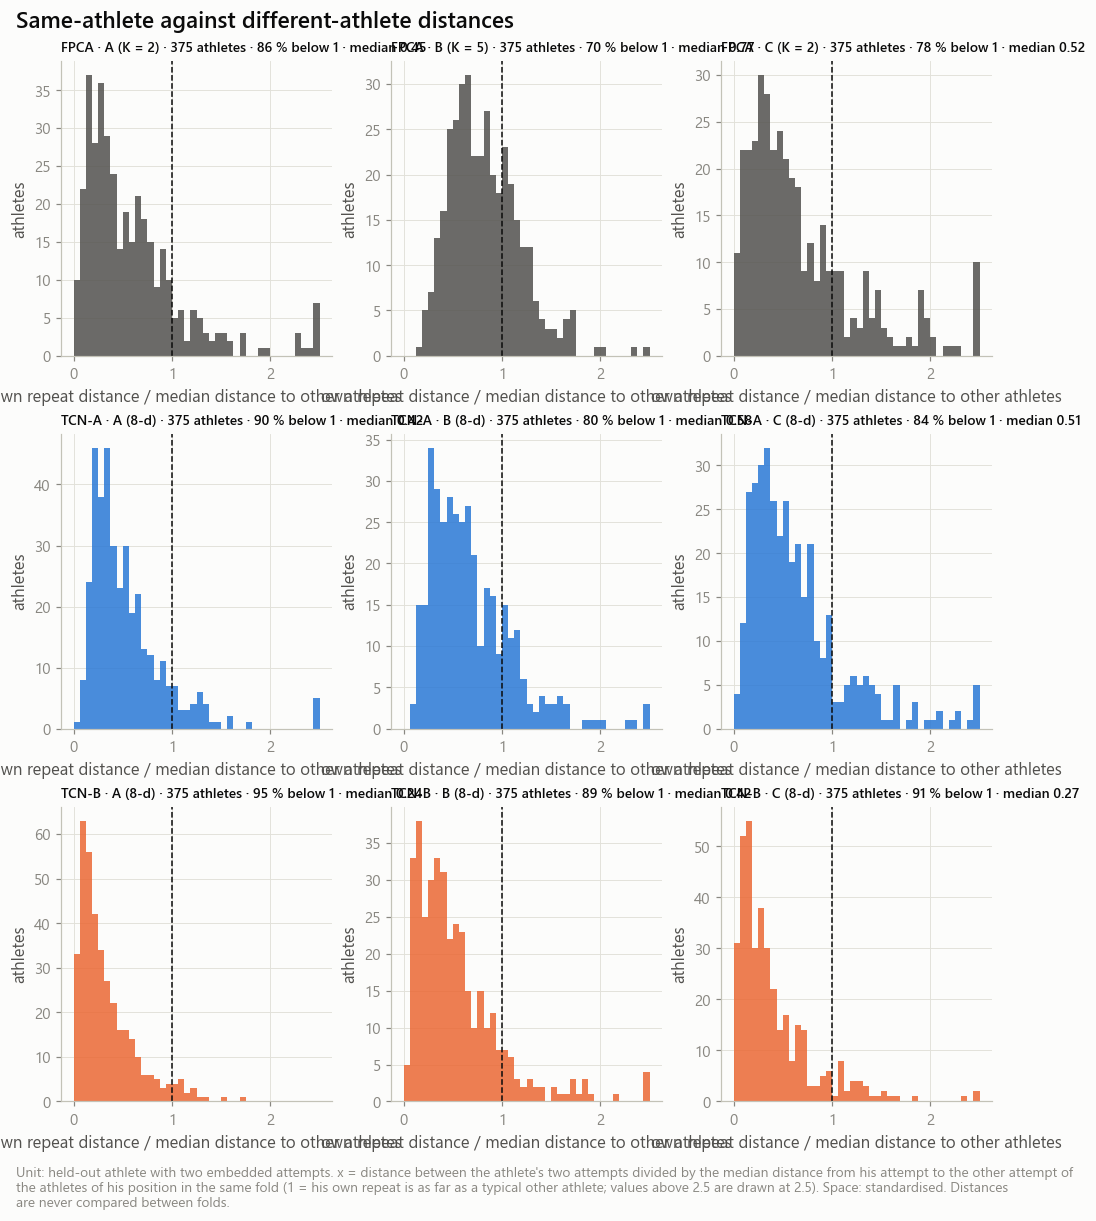

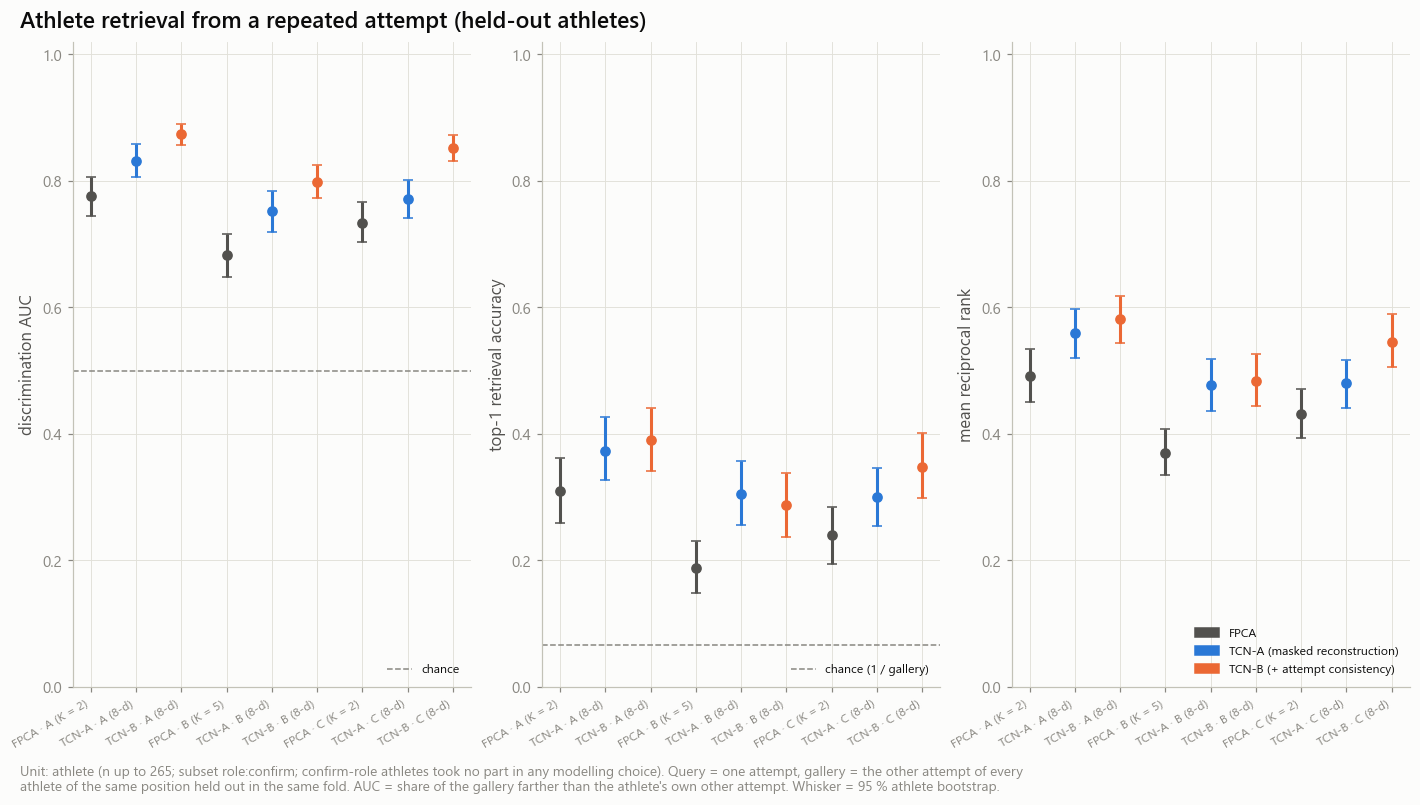

In [18]:
repeat, pairs = ev[rv.REPEAT.name], ev[rv.PAIRS.name]
main_methods = methods['method'].to_list()
within = (pl.col('scope') == 'within_position') & (pl.col('space') == 'standardised') & pl.col('method').is_in(main_methods)
cols = ['method', 'subset', 'n_athletes', 'gallery_mean', 'chance_top1', 'auc', 'auc_lower', 'auc_upper', 'top1', 'top1_lower',
        'top1_upper', 'topk', 'mrr', 'distance_ratio', 'cos_same', 'cos_diff']
display(Markdown('**Repeat-attempt discrimination and retrieval, within position** (unit: held-out athlete; standardised embedding)'))
display(repeat.filter(within & pl.col('subset').is_in(['role:confirm', 'role:design', 'all'])).select(cols).sort('subset', 'method'))
display(Markdown('**By draft cohort and by position** (same gallery; sample sizes are small in some groups)'))
display(repeat.filter(within & (pl.col('subset').str.starts_with('cohort:') | pl.col('subset').str.starts_with('position:')))
        .select('method', 'subset', 'n_athletes', 'chance_top1', 'auc', 'auc_lower', 'auc_upper', 'top1').sort('subset', 'method'))
display(Markdown('**Sensitivity to the gallery and to the metric** (all held-out athletes)'))
display(repeat.filter(pl.col('method').is_in(main_methods) & (pl.col('subset') == 'all'))
        .select('method', 'space', 'scope', 'n_athletes', 'gallery_mean', 'auc', 'auc_lower', 'auc_upper', 'top1', 'mrr')
        .sort('scope', 'space', 'method'))
display(Markdown('**Embedding stability under controlled truncation of the recording** (unit: held-out athlete)'))
display(ev[rv.TRUNC.name].sort('view', 'method'))

store.show(tf.plot_similarity(pairs, methods), 'AM03_05_same_vs_different_athlete_distances', publication=True,
           source='repr_pair_statistics', n=f'{pairs.filter(within)["nfl_id"].n_unique()} athletes with two attempts')
store.show(tf.plot_retrieval(repeat, methods), 'AM03_06_retrieval_performance', {'repeatability': repeat.filter(within)},
           publication=True, source='repr_repeatability', n=f'{method_summary["n_confirm"].max()} confirm athletes')

## 14 · Stopwatch redundancy probes

Two questions, in this order.

**1. How much of the official results does the embedding carry?** Ridge probes predict the official forty, the 10-yard split, weight and height from the athlete's mean embedding. They are fitted on some athletes and scored on others. Two protocols:

- `heldout_crossfit` (primary): fitted and scored on disjoint held-out athletes of the same fold. Every embedding involved comes from a model that did not see the athlete;
- `train_to_heldout`: fitted on the fold's training athletes, scored on its held-out athletes. It is the literal development-to-held-out transfer; an encoder that overfits its training athletes makes this probe look weaker, so it is shown beside the first and not instead of it.

`baseline` uses position alone; `value` uses position and embedding; `gain` is the partial R² of the embedding beyond position.

**2. Is what remains repeatable?** A low correlation with the stopwatch proves nothing: noise is uncorrelated with the stopwatch too. Each embedding dimension is therefore replaced by its residual after a cross-fitted linear prediction from position, official forty, 10-yard split, weight and height (`resid_official`), and additionally from the recording-window variables (`resid_official_window`). The residual embedding goes through the same repeat-attempt evaluation as in section 13. A residual AUC clearly above 0.5 on confirm athletes is the evidence this notebook is looking for.

Limits: the removal is linear, so a nonlinear function of the forty can survive it; and athletes without both official times are left out of the residual analysis.

**Official results from the embedding** (unit: athlete; held-out R²; gain = partial R² beyond position)

method,protocol,target,n_athletes,baseline,value,value_lower,value_upper,gain,gain_lower,gain_upper
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.551107,0.496729,0.602864,-0.017949,-0.054814,0.014554
"""FPCA_B_K5""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.54184,0.481956,0.605034,-0.038962,-0.101715,0.025665
"""FPCA_C_K2""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.54522,0.488763,0.598544,-0.031298,-0.067687,0.001597
"""TCNA_A""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.536084,0.477951,0.587386,-0.052015,-0.104431,-0.005762
"""TCNA_A_E16""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.533857,0.469836,0.58999,-0.057065,-0.128611,0.013932
"""TCNA_B""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.530824,0.468207,0.590386,-0.063943,-0.113474,-0.013264
"""TCNA_C""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.531724,0.46952,0.585714,-0.061902,-0.129372,-0.003615
"""TCNB_A""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.553738,0.4961,0.605665,-0.011982,-0.065538,0.032416
"""TCNB_A_E16""","""heldout_crossfit""","""cmb_combine_height""",418,0.559021,0.544795,0.483162,0.599406,-0.032262,-0.092892,0.020881


**Repeatability of the residual embedding** (unit: confirm-role held-out athlete, within position)

method,n_athletes,chance_top1,auc,auc_lower,auc_upper,top1,top1_lower,top1_upper,mrr
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""",265,0.066586,0.776179,0.744975,0.806438,0.309434,0.258443,0.362264,0.492283
"""FPCA_A_K2|resid_official""",265,0.066586,0.695215,0.664147,0.726657,0.198113,0.156604,0.245283,0.373552
"""FPCA_A_K2|resid_official_window""",265,0.066586,0.644962,0.615013,0.674318,0.156604,0.120755,0.19434,0.325742
"""FPCA_B_K5""",265,0.066586,0.68268,0.648413,0.715275,0.188679,0.149057,0.230236,0.370183
"""FPCA_B_K5|resid_official""",265,0.066586,0.702018,0.668987,0.73437,0.215094,0.171698,0.260425,0.389198
"""FPCA_B_K5|resid_official_window""",265,0.066586,0.664155,0.631169,0.695527,0.188679,0.150943,0.228302,0.360779
"""FPCA_C_K2""",265,0.066586,0.733702,0.702748,0.766353,0.239623,0.19434,0.284953,0.431706
"""FPCA_C_K2|resid_official""",265,0.066586,0.67522,0.643677,0.704842,0.192453,0.15283,0.233962,0.363679
"""FPCA_C_K2|resid_official_window""",265,0.066586,0.666235,0.63332,0.699026,0.171698,0.132075,0.211321,0.34893


**Rotation-invariant reliability** (unit: athlete; share of the embedding variance that lies between athletes, stratum = position × fold; per-dimension values depend on the rotation and are for orientation only)

method,space,n_athletes_repeat,n_sequences,icc_trace,icc_lower,icc_upper,icc_dim_min,icc_dim_median,icc_dim_max
str,str,i64,i64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""raw""",375,793,0.851733,0.79305,0.890496,0.357969,0.655616,0.953262
"""FPCA_B_K5""","""raw""",375,793,0.478528,0.339785,0.566137,0.175786,0.310254,0.534109
"""FPCA_C_K2""","""raw""",375,793,0.403023,0.207489,0.603012,0.370222,0.39385,0.417478
"""TCNA_A""","""raw""",375,793,0.738614,0.622535,0.824933,0.618258,0.73823,0.875909
"""TCNA_A_E16""","""raw""",375,793,0.723827,0.594582,0.833134,0.407266,0.700587,0.903904
"""TCNA_B""","""raw""",375,793,0.465322,0.318564,0.569118,0.356571,0.439108,0.637168
"""TCNA_C""","""raw""",375,793,0.426338,0.222879,0.620416,0.301856,0.441713,0.712802
"""TCNB_A""","""raw""",375,793,0.925027,0.898236,0.937213,0.906459,0.925495,0.943454
"""TCNB_A_E16""","""raw""",375,793,0.928466,0.91055,0.935404,0.908861,0.930821,0.94219


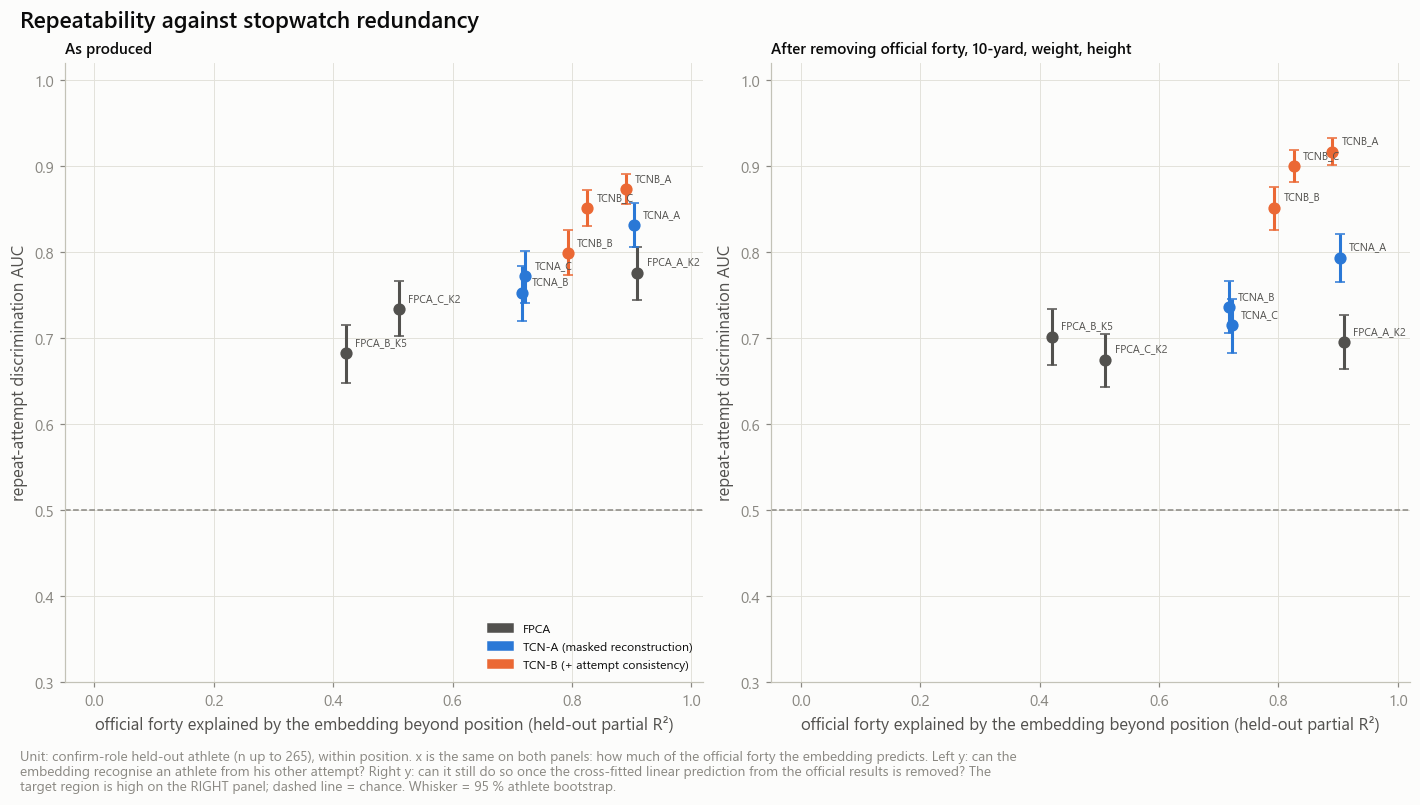

In [19]:
probes = ev[rv.PROBES.name]
official = [fe.FORTY, fe.TEN, fe.WEIGHT, fe.HEIGHT]
display(Markdown('**Official results from the embedding** (unit: athlete; held-out R²; gain = partial R² beyond position)'))
display(probes.filter(pl.col('target').is_in(official)).select('method', 'protocol', 'target', 'n_athletes', 'baseline', 'value',
                                                               'value_lower', 'value_upper', 'gain', 'gain_lower', 'gain_upper')
        .sort('target', 'protocol', 'method'))

residual_methods = [f'{m}|resid_{r}' for m in main_methods for r in rv.RESIDUALS]
display(Markdown('**Repeatability of the residual embedding** (unit: confirm-role held-out athlete, within position)'))
display(repeat.filter(pl.col('method').is_in([*main_methods, *residual_methods]) & (pl.col('scope') == 'within_position')
                      & (pl.col('space') == 'standardised') & (pl.col('subset') == 'role:confirm'))
        .select('method', 'n_athletes', 'chance_top1', 'auc', 'auc_lower', 'auc_upper', 'top1', 'top1_lower', 'top1_upper', 'mrr')
        .sort('method'))
display(Markdown('**Rotation-invariant reliability** (unit: athlete; share of the embedding variance that lies between athletes, '
                 'stratum = position × fold; per-dimension values depend on the rotation and are for orientation only)'))
display(ev[rv.ICC.name].sort('space', 'method'))

store.show(tf.plot_reliability_vs_redundancy(method_summary, methods), 'AM03_08_reliability_vs_stopwatch_redundancy',
           {'summary': method_summary}, publication=True, source='repr_method_summary',
           n=f'{method_summary["n_confirm"].max()} confirm athletes')

## 15 · Cohort and recording-window probes

**Draft cohort.** The 2025 recordings are about four times smoother than those of 2023 and 2024 (Phase 03). An encoder can learn the sensor generation. The cohort probe predicts the draft year from position alone (baseline) and from position plus embedding; the gain is what the embedding adds.

**Recording window, natural variation.** Between two attempts the athlete is the same and the recording is not. The change of the embedding between attempts is regressed on the change of first-frame speed, recorded duration and frames after the peak. The share explained (trace R² over dimensions, in-sample as in notebook 02) is the part of the attempt-to-attempt variation that follows the recording.

**Recording window, controlled.** The same held-out attempt is embedded again with the first or last 15 % or 30 % of its recorded points hidden. The shift is expressed relative to the median distance between different athletes.

**Recording variables from one attempt.** Attempt-level probes predict first-frame speed, duration, the share of the support covered, positional noise and the censoring flags from the embedding, beyond position.

**Draft cohort and position from the embedding** (unit: athlete; held-out accuracy)

method,protocol,target,n_athletes,baseline,value,value_lower,value_upper,gain,gain_lower,gain_upper
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.308612,0.270335,0.356459,0.100478,0.057416,0.149581
"""FPCA_B_K5""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.466507,0.423325,0.513218,0.258373,0.205742,0.313397
"""FPCA_C_K2""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.334928,0.29049,0.381639,0.126794,0.08122,0.178289
"""TCNA_A""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.452153,0.409091,0.5,0.244019,0.187739,0.301435
"""TCNA_A_E16""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.456938,0.413876,0.503648,0.248804,0.19378,0.307476
"""TCNA_B""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.509569,0.45933,0.566986,0.301435,0.237978,0.357715
"""TCNA_C""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.444976,0.394737,0.492823,0.236842,0.177033,0.287081
"""TCNB_A""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.284689,0.237978,0.325359,0.076555,0.027452,0.12201
"""TCNB_A_E16""","""heldout_crossfit""","""draft_cohort""",418,0.208134,0.334928,0.289474,0.379246,0.126794,0.072907,0.175897


**Recording variables from one attempt** (unit: attempt, athletes resampled; r2 gain = partial R² beyond position; auc gain = AUC − AUC of position alone). A variable that does not vary in this run has no row.

method,target,metric,n_athletes,n_obs,baseline,value,gain,gain_lower,gain_upper
str,str,str,i64,i64,f64,f64,f64,f64,f64
"""FPCA_A_K2""","""a_tan_roughness""","""r2""",418,793,0.044825,0.03674,-0.008464,-0.05194,0.027295
"""FPCA_B_K5""","""a_tan_roughness""","""r2""",418,793,0.044825,0.0458,0.001021,-0.057335,0.057249
"""FPCA_C_K2""","""a_tan_roughness""","""r2""",418,793,0.044825,-0.002526,-0.049572,-0.103788,-0.00855
"""TCNA_A""","""a_tan_roughness""","""r2""",418,793,0.044825,-0.006809,-0.054056,-0.12712,0.000783
"""TCNA_A_E16""","""a_tan_roughness""","""r2""",418,793,0.044825,-0.101068,-0.152739,-0.292544,-0.05563
"""TCNA_B""","""a_tan_roughness""","""r2""",418,793,0.044825,0.079845,0.036664,-0.045272,0.099721
"""TCNA_C""","""a_tan_roughness""","""r2""",418,793,0.044825,0.007171,-0.039421,-0.324519,0.103239
"""TCNB_A""","""a_tan_roughness""","""r2""",418,793,0.044825,-0.003379,-0.050465,-0.08245,-0.023557
"""TCNB_A_E16""","""a_tan_roughness""","""r2""",418,793,0.044825,-0.033722,-0.082232,-0.121909,-0.048893


**Attempt-to-attempt change of the embedding explained by the change of the recording window** (unit: athlete with two attempts)

method,space,n_athletes,r2_trace,r2_lower,r2_upper
str,str,i64,f64,f64,f64
"""FPCA_A_K2""","""raw""",375,0.600093,0.535718,0.712376
"""FPCA_B_K5""","""raw""",375,0.24592,0.185373,0.531493
"""FPCA_C_K2""","""raw""",375,0.868152,0.848711,0.937375
"""TCNA_A""","""raw""",375,0.60081,0.495853,0.743807
"""TCNA_A_E16""","""raw""",375,0.612302,0.465827,0.770409
"""TCNA_B""","""raw""",375,0.298432,0.213063,0.609545
"""TCNA_C""","""raw""",375,0.837379,0.766408,0.921788
"""TCNB_A""","""raw""",375,0.100083,0.090399,0.201467
"""TCNB_A_E16""","""raw""",375,0.094828,0.091359,0.184452


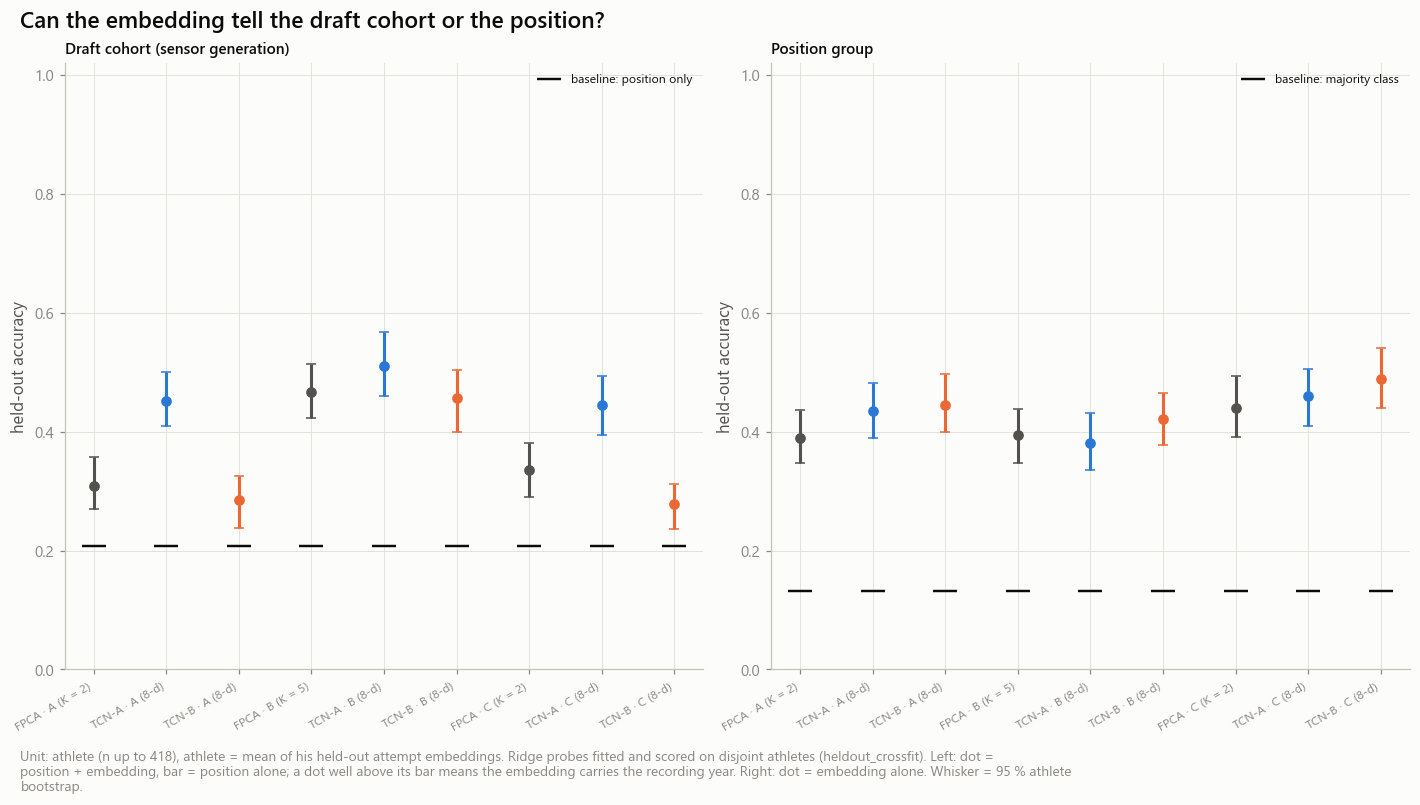

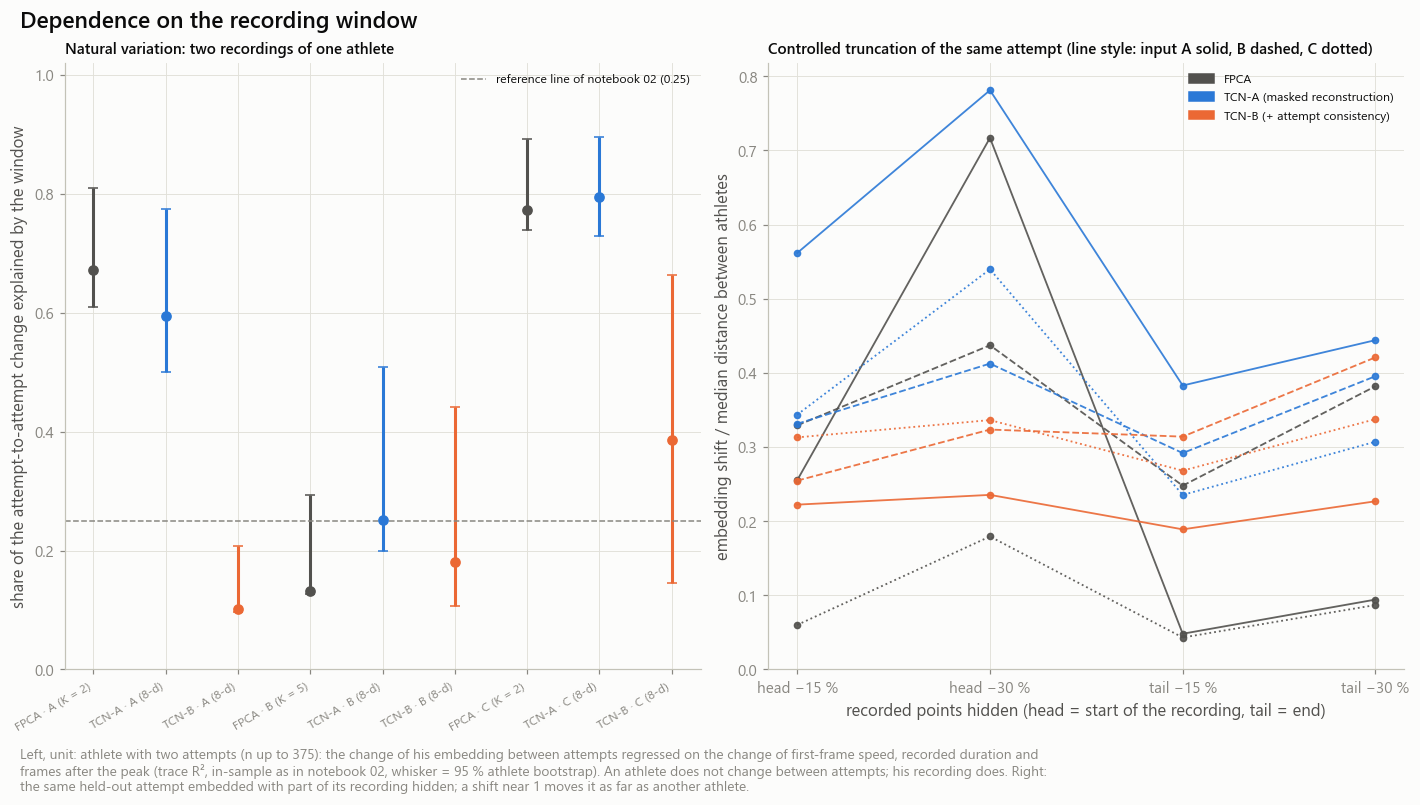

In [20]:
window = ev[rv.WINDOW.name]
display(Markdown('**Draft cohort and position from the embedding** (unit: athlete; held-out accuracy)'))
display(probes.filter(pl.col('target').is_in(['draft_cohort', 'position_group']))
        .select('method', 'protocol', 'target', 'n_athletes', 'baseline', 'value', 'value_lower', 'value_upper', 'gain', 'gain_lower',
                'gain_upper').sort('target', 'protocol', 'method'))
display(Markdown('**Recording variables from one attempt** (unit: attempt, athletes resampled; r2 gain = partial R² beyond position; '
                 'auc gain = AUC − AUC of position alone). A variable that does not vary in this run has no row.'))
display(probes.filter(pl.col('level') == 'attempt').select('method', 'target', 'metric', 'n_athletes', 'n_obs', 'baseline', 'value',
                                                          'gain', 'gain_lower', 'gain_upper').sort('target', 'method'))
display(Markdown('**Attempt-to-attempt change of the embedding explained by the change of the recording window** (unit: athlete with '
                 'two attempts)'))
display(window.sort('space', 'method'))

n_cohort = probes.filter(pl.col('target') == 'draft_cohort')['n_athletes'].max()
store.show(tf.plot_cohort_probe(probes, methods), 'AM03_09_cohort_and_position_probes',
           {'probes': probes.filter(pl.col('target').is_in(['draft_cohort', 'position_group']))}, source='repr_probes',
           n=f'{n_cohort} athletes')
store.show(tf.plot_window_dependence(window, ev[rv.TRUNC.name], methods, fcfg.window_reference), 'AM03_10_recording_window_dependence',
           {'window': window, 'truncation': ev[rv.TRUNC.name]}, publication=True,
           source='repr_window_dependence, repr_truncation_stability', n=f'{window["n_athletes"].max()} athletes with two attempts')

## 16 · FPCA comparison

One row per method, the FPCA benchmarks of notebook 02 beside the encoders, on the same held-out athletes and support.

| Axis | Column | Better is |
|---|---|---|
| Repeat-attempt discrimination | `auc` (confirm athletes) | higher |
| Athlete retrieval | `top1` against `chance_top1` | higher |
| Stopwatch redundancy | `forty_partial_r2`, then `resid_auc` | a high `resid_auc` whatever the redundancy |
| Recording-window dependence | `window_r2`, `truncation_shift_max`, `resid_window_auc` | lower, lower, higher |
| Cohort predictability | `cohort_gain` | lower |
| Held-out reconstruction | `rmse`, `rmse_masked` | lower, but never decisive |
| Dimensionality | `embedding_dim` | – |
| Complexity and cost | `n_parameters`, `train_seconds` | – |

The examples figure shows pairs of athletes of the same position with the same official forty and how far apart each method places their runs. It illustrates; it does not test.

**Evidence by method** (AUC columns: confirm-role held-out athletes, within position)

method,embedding_dim,n_parameters,train_seconds,rmse,rmse_masked,value_unit,n_confirm,auc,auc_lower,auc_upper,top1,chance_top1,icc_trace
str,i64,i64,f64,f64,f64,str,i64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""",2,48,null,0.100867,0.169396,"""yd/s""",265,0.776179,0.744975,0.806438,0.309434,0.066586,0.851733
"""FPCA_B_K5""",5,60,null,0.162087,0.336494,"""yd/s²""",265,0.68268,0.648413,0.715275,0.188679,0.066586,0.478528
"""FPCA_C_K2""",2,48,null,0.152378,0.234161,"""yd/s""",265,0.733702,0.702748,0.766353,0.239623,0.066586,0.403023
"""TCNA_A""",8,32761,210.5232,0.207061,0.113562,"""yd/s""",265,0.831626,0.805972,0.857686,0.373585,0.066586,0.738614
"""TCNA_A_E16""",16,33793,196.627886,0.204167,0.110391,"""yd/s""",265,0.854727,0.831589,0.878579,0.409434,0.066586,0.723827
"""TCNA_B""",8,30291,171.624318,0.346828,0.287646,"""yd/s²""",265,0.753148,0.719662,0.783622,0.30566,0.066586,0.465322
"""TCNA_C""",8,31461,177.305719,0.294386,0.209222,"""yd/s""",265,0.771938,0.740614,0.801803,0.3,0.066586,0.426338
"""TCNB_A""",8,32761,476.989689,0.235611,0.124663,"""yd/s""",265,0.873452,0.856494,0.890426,0.390566,0.066586,0.925027
"""TCNB_A_E16""",16,33793,423.095506,0.23486,0.117533,"""yd/s""",265,0.88011,0.86419,0.896704,0.401887,0.066586,0.928466


method,forty_r2,forty_partial_r2,ten_partial_r2,body_partial_r2,resid_auc,resid_auc_lower,resid_auc_upper,resid_window_auc,window_r2,cohort_gain,position_accuracy,truncation_shift_max,rank_share_min,collapsed
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""FPCA_A_K2""",0.976464,0.909382,0.523165,0.303983,0.695215,0.664147,0.726657,0.644962,0.670966,0.100478,0.389952,0.71679,0.582469,false
"""FPCA_B_K5""",0.849511,0.420595,0.198699,0.088317,0.702018,0.668987,0.73437,0.664155,0.131292,0.258373,0.394737,0.437169,0.344005,false
"""FPCA_C_K2""",0.872735,0.510011,0.172712,0.084514,0.67522,0.643677,0.704842,0.666235,0.773298,0.126794,0.440191,0.179342,0.758055,false
"""TCNA_A""",0.974824,0.90307,0.532004,0.249685,0.793806,0.765542,0.821618,0.750071,0.594742,0.244019,0.435407,0.781062,0.16079,true
"""TCNA_A_E16""",0.976621,0.909988,0.534964,0.259911,0.825519,0.799216,0.852476,0.77103,0.625036,0.248804,0.433014,0.75194,0.086445,true
"""TCNA_B""",0.926441,0.716789,0.429066,0.220249,0.736368,0.705885,0.766273,0.694308,0.252175,0.301435,0.380383,0.412489,0.221626,true
"""TCNA_C""",0.927703,0.721646,0.412284,0.205694,0.715289,0.683342,0.745697,0.735744,0.794689,0.236842,0.45933,0.539615,0.229377,true
"""TCNB_A""",0.971405,0.889904,0.544293,0.318763,0.916759,0.900917,0.932442,0.895136,0.102067,0.076555,0.444976,0.23543,0.254536,false
"""TCNB_A_E16""",0.973987,0.899847,0.544621,0.317984,0.935111,0.920535,0.948459,0.919309,0.094051,0.126794,0.454545,0.280477,0.193265,true


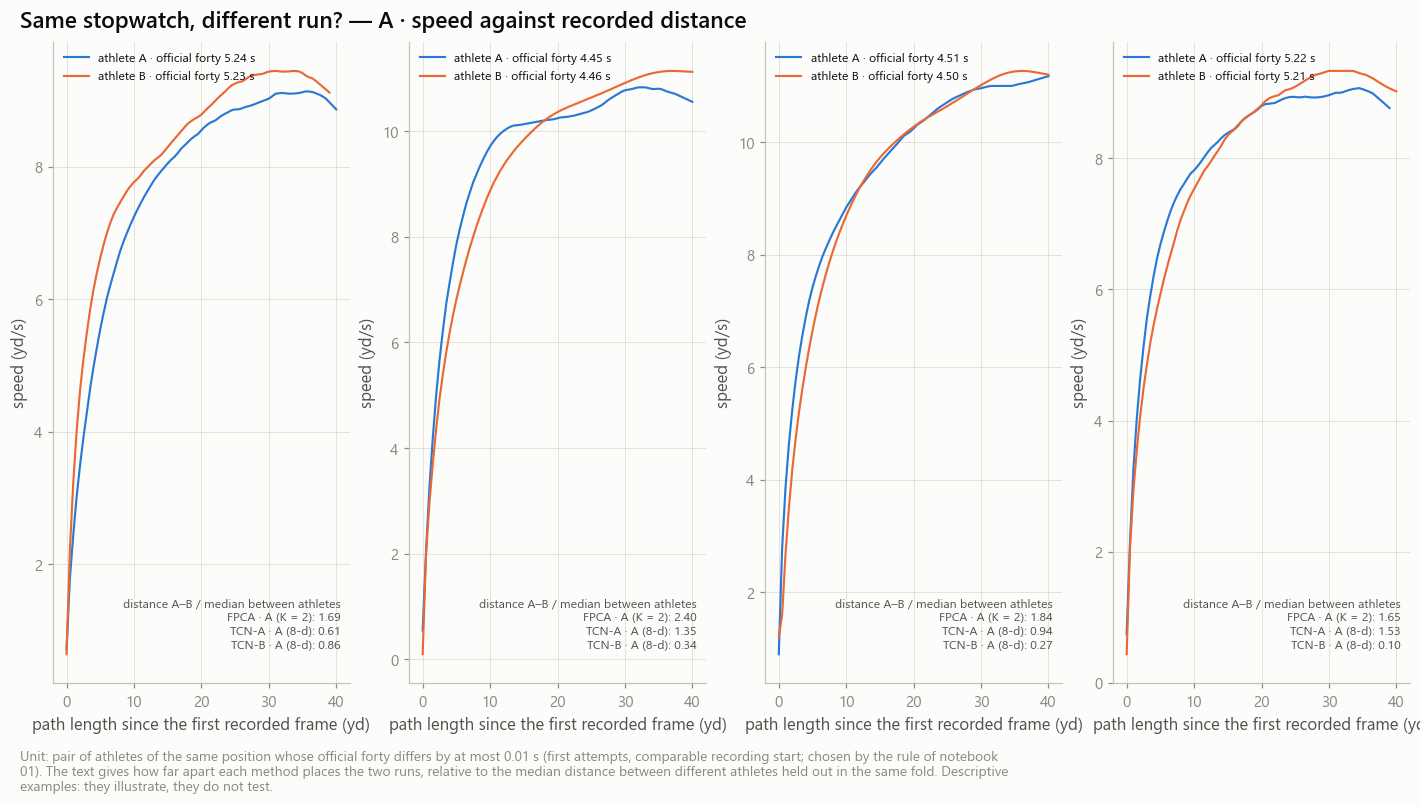

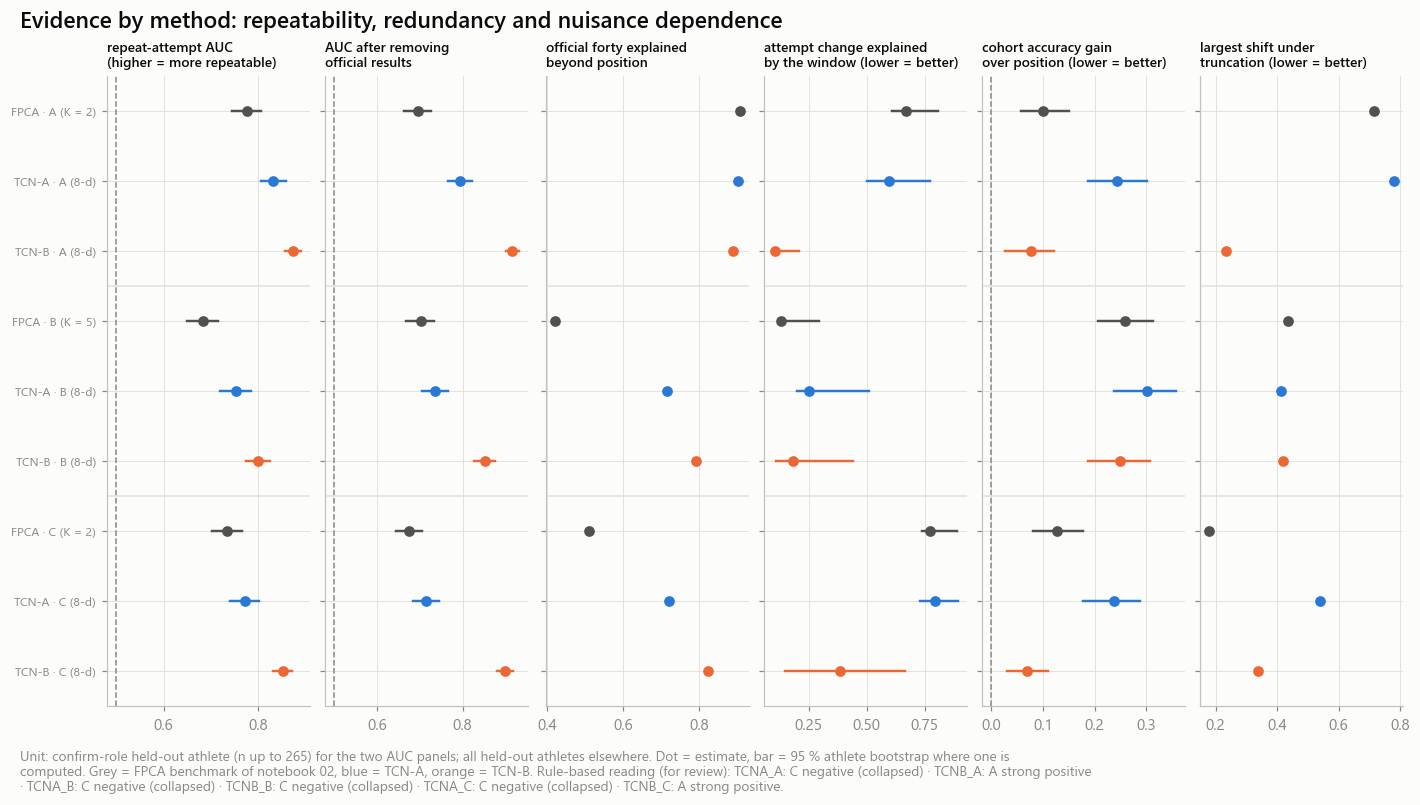

In [21]:
display(Markdown('**Evidence by method** (AUC columns: confirm-role held-out athletes, within position)'))
display(method_summary.select('method', 'embedding_dim', 'n_parameters', 'train_seconds', 'rmse', 'rmse_masked', 'value_unit',
                              'n_confirm', 'auc', 'auc_lower', 'auc_upper', 'top1', 'chance_top1', 'icc_trace'))
display(method_summary.select('method', 'forty_r2', 'forty_partial_r2', 'ten_partial_r2', 'body_partial_r2', 'resid_auc',
                              'resid_auc_lower', 'resid_auc_upper', 'resid_window_auc', 'window_r2', 'cohort_gain',
                              'position_accuracy', 'truncation_shift_max', 'rank_share_min', 'collapsed'))

# Pairs of athletes with the same official forty (rule of notebook 01), kept when both are held out in the same fold.
pair_methods = [fpca_specs[REPRESENTATIONS.index(PRIMARY)].method, 'TCNA_A', 'TCNB_A']
candidates = eda.similar_forty_pairs(summary, athletes, 60)
examples = [e for e in tf.pair_examples(candidates, emb.filter(pl.col('method').is_in(pair_methods)), pair_methods)
            if len(e['distance']) == len(pair_methods)][:4]
labels = dict(methods.select('method', 'label').iter_rows())
store.show(tf.plot_pair_examples(examples, curves[PRIMARY], labels, PRIMARY), 'AM03_11_same_forty_athlete_pairs',
           source='sequence_summary, athlete_registry, embeddings', n=f'{len(examples)} pairs of athletes (illustration)')
store.show(tf.plot_final_comparison(method_summary, methods, verdict), 'AM03_12_evidence_by_method', {'summary': method_summary},
           publication=True, source='repr_method_summary, repr_verdict', n=f'{method_summary["n_confirm"].max()} confirm athletes')

## 17 · Statistical uncertainty

- **Unit.** The athlete. An athlete is held out once, contributes one value per metric, and is resampled as a whole.
- **Intervals.** 95 % percentile bootstrap over athletes (1,000 replicates in full mode, 300 for probes and the window regression).
- **Paired comparisons.** An encoder and its FPCA reference are compared on the athletes both score, with the same resamples, so the interval is that of the difference and not of two separate estimates.
- **What the intervals do not include.** The variation between training runs of the same encoder (one seed per fold model), and the variation between split repeats (repeat 0 only). A difference that is small against the interval should not be read as a ranking.
- **Multiplicity.** Three inputs, two objectives and several metrics are reported. The pre-declared read-out is the within-position AUC and the residual AUC on confirm athletes for input A; everything else is supporting evidence.
- **Sample size.** About 293 confirm athletes, of whom those with two eligible attempts enter the repeatability metrics; per position and per cohort the groups are much smaller and their intervals wide.

In [22]:
paired = ev[rv.PAIRED.name]
display(Markdown('**Encoder − FPCA of the same input, paired on athletes** (unit: athlete; standardised embedding, within position)'))
display(paired.filter((pl.col('space') == 'standardised') & pl.col('method').is_in(main_methods))
        .select('method', 'reference', 'subset', 'metric', 'n_athletes', 'estimate', 'reference_estimate', 'difference', 'diff_lower',
                'diff_upper').sort('subset', 'metric', 'method'))
display(Markdown('**Same comparison on the residual embeddings** (confirm athletes)'))
display(paired.filter((pl.col('space') == 'standardised') & pl.col('method').str.contains('resid_', literal=True)
                      & (pl.col('subset') == 'role:confirm'))
        .select('method', 'reference', 'metric', 'n_athletes', 'estimate', 'reference_estimate', 'difference', 'diff_lower', 'diff_upper')
        .sort('metric', 'method'))
sensitivity = method_summary.filter(pl.col('representation') == PRIMARY).select(
    'method', 'embedding_dim', 'n_parameters', 'rmse', 'auc', 'auc_lower', 'auc_upper', 'resid_auc', 'forty_partial_r2', 'window_r2',
    'rank_share_min')
display(Markdown('**Embedding size on input A: 8 against 16 dimensions** (sensitivity; the 16-dimensional models are never selected)'))
display(sensitivity)

**Encoder − FPCA of the same input, paired on athletes** (unit: athlete; standardised embedding, within position)

method,reference,subset,metric,n_athletes,estimate,reference_estimate,difference,diff_lower,diff_upper
str,str,str,str,i64,f64,f64,f64,f64,f64
"""TCNA_A""","""FPCA_A_K2""","""all""","""auc""",375,0.827261,0.773263,0.053998,0.036282,0.070483
"""TCNA_A_E16""","""FPCA_A_K2""","""all""","""auc""",375,0.851897,0.773263,0.078634,0.060612,0.095836
"""TCNA_B""","""FPCA_B_K5""","""all""","""auc""",375,0.75443,0.684163,0.070266,0.04549,0.094439
"""TCNA_C""","""FPCA_C_K2""","""all""","""auc""",375,0.757948,0.719341,0.038607,0.028934,0.048113
"""TCNB_A""","""FPCA_A_K2""","""all""","""auc""",375,0.868961,0.773263,0.095698,0.06961,0.121943
"""TCNB_A_E16""","""FPCA_A_K2""","""all""","""auc""",375,0.875614,0.773263,0.102351,0.076879,0.128102
"""TCNB_B""","""FPCA_B_K5""","""all""","""auc""",375,0.803718,0.684163,0.119554,0.089328,0.147955
"""TCNB_C""","""FPCA_C_K2""","""all""","""auc""",375,0.84126,0.719341,0.12192,0.095874,0.150675
"""TCNA_A""","""FPCA_A_K2""","""all""","""rr""",375,0.560536,0.491514,0.069022,0.041797,0.098045


**Same comparison on the residual embeddings** (confirm athletes)

method,reference,metric,n_athletes,estimate,reference_estimate,difference,diff_lower,diff_upper
str,str,str,i64,f64,f64,f64,f64,f64
"""TCNA_A_E16|resid_official""","""FPCA_A_K2|resid_official""","""auc""",265,0.825519,0.695215,0.130305,0.106751,0.155473
"""TCNA_A_E16|resid_official_window""","""FPCA_A_K2|resid_official_window""","""auc""",265,0.77103,0.644962,0.126068,0.095243,0.155615
"""TCNA_A|resid_official""","""FPCA_A_K2|resid_official""","""auc""",265,0.793806,0.695215,0.098591,0.074651,0.122761
"""TCNA_A|resid_official_window""","""FPCA_A_K2|resid_official_window""","""auc""",265,0.750071,0.644962,0.105109,0.074981,0.134361
"""TCNA_B|resid_official""","""FPCA_B_K5|resid_official""","""auc""",265,0.736368,0.702018,0.03435,0.005646,0.061827
"""TCNA_B|resid_official_window""","""FPCA_B_K5|resid_official_window""","""auc""",265,0.694308,0.664155,0.030153,-0.00175,0.063872
"""TCNA_C|resid_official""","""FPCA_C_K2|resid_official""","""auc""",265,0.715289,0.67522,0.040069,0.027565,0.053763
"""TCNA_C|resid_official_window""","""FPCA_C_K2|resid_official_window""","""auc""",265,0.735744,0.666235,0.069509,0.04652,0.093857
"""TCNB_A_E16|resid_official""","""FPCA_A_K2|resid_official""","""auc""",265,0.935111,0.695215,0.239897,0.206256,0.272938


**Embedding size on input A: 8 against 16 dimensions** (sensitivity; the 16-dimensional models are never selected)

method,embedding_dim,n_parameters,rmse,auc,auc_lower,auc_upper,resid_auc,forty_partial_r2,window_r2,rank_share_min
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""FPCA_A_K2""",2,48,0.100867,0.776179,0.744975,0.806438,0.695215,0.909382,0.670966,0.582469
"""TCNA_A""",8,32761,0.207061,0.831626,0.805972,0.857686,0.793806,0.90307,0.594742,0.16079
"""TCNA_A_E16""",16,33793,0.204167,0.854727,0.831589,0.878579,0.825519,0.909988,0.625036,0.086445
"""TCNB_A""",8,32761,0.235611,0.873452,0.856494,0.890426,0.916759,0.889904,0.102067,0.254536
"""TCNB_A_E16""",16,33793,0.23486,0.88011,0.86419,0.896704,0.935111,0.899847,0.094051,0.193265


## 18 · Saved figures and result tables

Everything is written under the folders listed at the top of the notebook; a smoke run writes under `_sample` and can never replace a full run.

| Kind | Names |
|---|---|
| Tables (CSV + Parquet) | `tcn_design_sweep`, `tcn_a_training_history`, `tcn_a_fold_fits`, `tcn_b_training_history`, `tcn_b_fold_fits`, `tcn_e16_*`, `repr_methods`, `repr_repeatability`, `repr_paired_comparisons`, `repr_trace_reliability`, `repr_collapse`, `repr_covariance_spectrum`, `repr_probes`, `repr_window_dependence`, `repr_truncation_stability`, `repr_reconstruction`, `repr_method_summary`, `repr_verdict` |
| Datasets (Parquet) | `fpca_ref_attempt_embeddings`, `tcn_a_attempt_embeddings`, `tcn_b_attempt_embeddings`, `tcn_e16_attempt_embeddings`, the matching `*_sequence_reconstruction`, `repr_athlete_embeddings`, `repr_pair_statistics` |
| Models | `tcn/<method>__r<repeat>_f<fold>.pt`: weights, configuration, fold normalisation (support, mean, scale, noise), training athletes, provenance; `tcn/_models.json` |
| JSON | `tcn_experiment_manifest.json` |
| Figures | `AM03_01` to `AM03_12` (PNG 300 DPI + SVG; PDF for `AM03_01`, `02`, `04`, `05`, `06`, `08`, `10`, `12`) |

Grain and keys of every table are in its `.schema.json` sidecar. Embedding tables keep the sequence identifier, the athlete, the split repeat, the outer fold and the role of the athlete in that fold.

In [23]:
table_files = sorted(p.name for pattern in ('repr_*.csv', 'tcn_*.csv') for p in store.tables_dir.glob(pattern))
data_files = sorted(p.name for pattern in ('repr_*.parquet', 'tcn_*.parquet', 'fpca_ref_*.parquet') for p in store.data_dir.glob(pattern))
figure_files = sorted(p.name for p in store.figures_dir.glob('AM03_*.png'))
model_dir = store.models_dir / 'tcn'
model_files = sorted(p.name for p in model_dir.glob('*')) if model_dir.is_dir() else []
display(Markdown(f'**Tables** ({cfg.paths.rel(store.tables_dir)}): ' + (', '.join(table_files) or 'none (SAVE_TABLES is off)')))
display(Markdown(f'**Datasets** ({cfg.paths.rel(store.data_dir)}): ' + (', '.join(data_files) or 'none (SAVE_TABLES is off)')))
display(Markdown(f'**Figures** ({cfg.paths.rel(store.figures_dir)}): ' + (', '.join(figure_files) or 'none (SAVE_FIGURES is off)')))
display(Markdown(f'**Fold models** ({cfg.paths.rel(model_dir)}): {len(model_files)} file(s)' + ('' if model_files else ' — SAVE_MODELS is off')))

conclusions = rv.conclusions_markdown(method_summary, verdict, ecfg, controls.run_mode)
if controls.save_tables:
    store.write_json('tcn_experiment_manifest', {
        'notebook': '03_self_supervised_tcn', 'seed': controls.seed, 'device': device,
        'question': 'Can a neural network discover a stable, athlete-specific movement signature beyond what official Combine '
                    'results and recording artifacts already explain?',
        'scientific_status': 'technical check only (smoke run)' if controls.smoke else 'full-population run',
        'evaluation': 'inductive: every held-out embedding comes from a fold model that excluded the athlete; read-out on '
                      'confirm-role athletes; split repeat 0',
        'nfl_outcomes_used': False,
        'tuning_budget': {'compared_on_design_athletes': {'consistency': [list(g) for g in CONSISTENCY_GRID]},
                          'selected': {'consistency': CONSISTENCY_KIND, 'weight': CONSISTENCY_WEIGHT, 'reason': CONSISTENCY_REASON},
                          'declared_sensitivity': {'embedding_dim': [8, 16] if RUN_SENSITIVITY_16 else [8]},
                          'fixed_not_tuned': ['architecture', 'optimiser', 'masking', 'noise scale', 'early-stopping rule',
                                              'probe ridge penalty', 'collapse lines']},
        'tcn_a': tcfg_a.params(), 'tcn_b': tcfg_b.params(), 'evaluation_config': ecfg.params(),
        'augmentations': [{'transformation': a, 'status': b, 'justification': c} for a, b, c in tcn.AUGMENTATIONS],
        'methods': methods.to_dicts(), 'verdict': verdict.to_dicts(), 'conclusions': conclusions,
        'n_sequences': ss.n, 'n_athletes': int(np.unique(ss.nfl_ids).size), 'n_design_athletes': n_design,
        'n_confirm_athletes': n_confirm, 'split_repeats_evaluated': REPEATS, 'outer_folds': int(splits['outer_fold'].n_unique()),
        'fpca_reference': {'k': K, 'model_key': FPCA_KEY, 'models_loaded_from_disk': bool(on_disk)},
        'validation_checks_passed': int((validation_report['status'] == 'PASS').sum()),
        'inputs': {'notebook_00_written_at': previous.get('written_at'),
                   'files': [cfg.paths.rel(p) for p in [*STAGE_FILES, store.parquet(ck.WINDOWS), store.parquet(amd.ATHLETES)]]},
        'outputs': {'tables': table_files, 'datasets': data_files, 'figures': figure_files, 'models': model_files},
        'versions': {'torch': torch.__version__, 'numpy': np.__version__, 'polars': pl.__version__}})

**Tables** (reports/tables/advanced_movement): repr_collapse.csv, repr_covariance_spectrum.csv, repr_method_summary.csv, repr_methods.csv, repr_paired_comparisons.csv, repr_probes.csv, repr_reconstruction.csv, repr_repeatability.csv, repr_trace_reliability.csv, repr_truncation_stability.csv, repr_verdict.csv, repr_window_dependence.csv, tcn_a_fold_fits.csv, tcn_a_training_history.csv, tcn_b_fold_fits.csv, tcn_b_training_history.csv, tcn_design_sweep.csv, tcn_e16_fold_fits.csv, tcn_e16_training_history.csv

**Datasets** (warehouse/gold/advanced_movement): fpca_ref_attempt_embeddings.parquet, fpca_ref_sequence_reconstruction.parquet, repr_athlete_embeddings.parquet, repr_collapse.parquet, repr_covariance_spectrum.parquet, repr_method_summary.parquet, repr_methods.parquet, repr_pair_statistics.parquet, repr_paired_comparisons.parquet, repr_probes.parquet, repr_reconstruction.parquet, repr_repeatability.parquet, repr_trace_reliability.parquet, repr_truncation_stability.parquet, repr_verdict.parquet, repr_window_dependence.parquet, tcn_a_attempt_embeddings.parquet, tcn_a_fold_fits.parquet, tcn_a_sequence_reconstruction.parquet, tcn_a_training_history.parquet, tcn_b_attempt_embeddings.parquet, tcn_b_fold_fits.parquet, tcn_b_sequence_reconstruction.parquet, tcn_b_training_history.parquet, tcn_design_sweep.parquet, tcn_e16_attempt_embeddings.parquet, tcn_e16_fold_fits.parquet, tcn_e16_sequence_reconstruction.parquet, tcn_e16_training_history.parquet

**Figures** (reports/figures/advanced_movement): AM03_01_architecture_and_input.png, AM03_02_masked_reconstruction_examples.png, AM03_02_masked_reconstruction_examples_tcn_a.png, AM03_03_learning_curves.png, AM03_04_reconstruction_fpca_tcn_a_tcn_b.png, AM03_05_same_vs_different_athlete_distances.png, AM03_06_retrieval_performance.png, AM03_07_collapse_diagnostics.png, AM03_08_reliability_vs_stopwatch_redundancy.png, AM03_09_cohort_and_position_probes.png, AM03_10_recording_window_dependence.png, AM03_11_same_forty_athlete_pairs.png, AM03_12_evidence_by_method.png

**Fold models** (artifacts/models/advanced_movement/tcn): 41 file(s)

## 19 · Evidence-based conclusions

The text below is generated from `repr_method_summary` and `repr_verdict` of this run. Nothing is asserted from expectation, and a smoke run says that its numbers must not be interpreted.

In [24]:
display(Markdown(conclusions))

_Generated from `repr_method_summary` and `repr_verdict` of this run (`RUN_MODE = 'full'`). Read-out: confirm-role held-out athletes, within position, 95 % athlete-bootstrap intervals. Labels are heuristic._

**A · speed against recorded distance**
- FPCA · A (K = 2) (2 dimensions, 48 parameters): reconstruction RMSE 0.101 yd/s (masked 0.169); repeat-attempt AUC 0.776 [0.745, 0.806], top-1 0.309 (chance 0.067); official forty explained beyond position 0.91; AUC after removing official results 0.695 [0.664, 0.727], and the window 0.645; attempt-to-attempt change explained by the window 0.67; cohort accuracy gain 0.10.
- TCN-A · A (8-d) (8 dimensions, 32761 parameters): reconstruction RMSE 0.207 yd/s (masked 0.114); repeat-attempt AUC 0.832 [0.806, 0.858], top-1 0.374 (chance 0.067); official forty explained beyond position 0.90; AUC after removing official results 0.794 [0.766, 0.822], and the window 0.750; attempt-to-attempt change explained by the window 0.59; cohort accuracy gain 0.24; **collapsed**.
- TCN-A · A (16-d) (16 dimensions, 33793 parameters): reconstruction RMSE 0.204 yd/s (masked 0.110); repeat-attempt AUC 0.855 [0.832, 0.879], top-1 0.409 (chance 0.067); official forty explained beyond position 0.91; AUC after removing official results 0.826 [0.799, 0.852], and the window 0.771; attempt-to-attempt change explained by the window 0.63; cohort accuracy gain 0.25; **collapsed**.
- TCN-B · A (8-d) (8 dimensions, 32761 parameters): reconstruction RMSE 0.236 yd/s (masked 0.125); repeat-attempt AUC 0.873 [0.856, 0.890], top-1 0.391 (chance 0.067); official forty explained beyond position 0.89; AUC after removing official results 0.917 [0.901, 0.932], and the window 0.895; attempt-to-attempt change explained by the window 0.10; cohort accuracy gain 0.08.
- TCN-B · A (16-d) (16 dimensions, 33793 parameters): reconstruction RMSE 0.235 yd/s (masked 0.118); repeat-attempt AUC 0.880 [0.864, 0.897], top-1 0.402 (chance 0.067); official forty explained beyond position 0.90; AUC after removing official results 0.935 [0.921, 0.948], and the window 0.919; attempt-to-attempt change explained by the window 0.09; cohort accuracy gain 0.13; **collapsed**.

**B · acceleration against speed (rising phase)**
- FPCA · B (K = 5) (5 dimensions, 60 parameters): reconstruction RMSE 0.162 yd/s² (masked 0.336); repeat-attempt AUC 0.683 [0.648, 0.715], top-1 0.189 (chance 0.067); official forty explained beyond position 0.42; AUC after removing official results 0.702 [0.669, 0.734], and the window 0.664; attempt-to-attempt change explained by the window 0.13; cohort accuracy gain 0.26.
- TCN-A · B (8-d) (8 dimensions, 30291 parameters): reconstruction RMSE 0.347 yd/s² (masked 0.288); repeat-attempt AUC 0.753 [0.720, 0.784], top-1 0.306 (chance 0.067); official forty explained beyond position 0.72; AUC after removing official results 0.736 [0.706, 0.766], and the window 0.694; attempt-to-attempt change explained by the window 0.25; cohort accuracy gain 0.30; **collapsed**.
- TCN-B · B (8-d) (8 dimensions, 30291 parameters): reconstruction RMSE 0.511 yd/s² (masked 0.301); repeat-attempt AUC 0.799 [0.774, 0.826], top-1 0.287 (chance 0.067); official forty explained beyond position 0.79; AUC after removing official results 0.852 [0.826, 0.876], and the window 0.833; attempt-to-attempt change explained by the window 0.18; cohort accuracy gain 0.25; **collapsed**.

**C · speed against elapsed time**
- FPCA · C (K = 2) (2 dimensions, 48 parameters): reconstruction RMSE 0.152 yd/s (masked 0.234); repeat-attempt AUC 0.734 [0.703, 0.766], top-1 0.240 (chance 0.067); official forty explained beyond position 0.51; AUC after removing official results 0.675 [0.644, 0.705], and the window 0.666; attempt-to-attempt change explained by the window 0.77; cohort accuracy gain 0.13.
- TCN-A · C (8-d) (8 dimensions, 31461 parameters): reconstruction RMSE 0.294 yd/s (masked 0.209); repeat-attempt AUC 0.772 [0.741, 0.802], top-1 0.300 (chance 0.067); official forty explained beyond position 0.72; AUC after removing official results 0.715 [0.683, 0.746], and the window 0.736; attempt-to-attempt change explained by the window 0.79; cohort accuracy gain 0.24; **collapsed**.
- TCN-B · C (8-d) (8 dimensions, 31461 parameters): reconstruction RMSE 0.491 yd/s (masked 0.180); repeat-attempt AUC 0.851 [0.831, 0.872], top-1 0.347 (chance 0.067); official forty explained beyond position 0.83; AUC after removing official results 0.900 [0.882, 0.918], and the window 0.874; attempt-to-attempt change explained by the window 0.39; cohort accuracy gain 0.07.

**Go / no-go (rule-based, for review)**
- `TCNA_A` against `FPCA_A_K2`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance increased, reconstruction worse. Δ AUC +0.055 [+0.035, +0.076]; Δ residual AUC +0.099 [+0.075, +0.123]; residual AUC lower bound +0.766; Δ RMSE +0.106 [+0.097, +0.115]; window / cohort excess over the reference -0.076, +0.144.
- `TCNA_A_E16` against `FPCA_A_K2`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance increased, reconstruction worse. Δ AUC +0.079 [+0.059, +0.099]; Δ residual AUC +0.130 [+0.107, +0.155]; residual AUC lower bound +0.799; Δ RMSE +0.103 [+0.095, +0.112]; window / cohort excess over the reference -0.046, +0.148.
- `TCNA_B` against `FPCA_B_K5`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance increased, reconstruction worse. Δ AUC +0.070 [+0.041, +0.100]; Δ residual AUC +0.034 [+0.006, +0.062]; residual AUC lower bound +0.706; Δ RMSE +0.185 [+0.167, +0.204]; window / cohort excess over the reference +0.121, +0.043.
- `TCNA_C` against `FPCA_C_K2`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance increased, reconstruction worse. Δ AUC +0.038 [+0.028, +0.049]; Δ residual AUC +0.040 [+0.028, +0.054]; residual AUC lower bound +0.683; Δ RMSE +0.142 [+0.083, +0.225]; window / cohort excess over the reference +0.021, +0.110.
- `TCNB_A` against `FPCA_A_K2`: **A strong positive** — repeatability better, non-redundant repeatability better, nuisance controlled, reconstruction worse. Δ AUC +0.097 [+0.065, +0.128]; Δ residual AUC +0.222 [+0.188, +0.255]; residual AUC lower bound +0.901; Δ RMSE +0.135 [+0.122, +0.148]; window / cohort excess over the reference -0.569, -0.024.
- `TCNB_A_E16` against `FPCA_A_K2`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance controlled, reconstruction worse. Δ AUC +0.104 [+0.071, +0.136]; Δ residual AUC +0.240 [+0.206, +0.273]; residual AUC lower bound +0.921; Δ RMSE +0.134 [+0.122, +0.146]; window / cohort excess over the reference -0.577, +0.026.
- `TCNB_B` against `FPCA_B_K5`: **C negative (collapsed)** — repeatability better, non-redundant repeatability better, nuisance controlled, reconstruction worse. Δ AUC +0.116 [+0.080, +0.153]; Δ residual AUC +0.150 [+0.113, +0.187]; residual AUC lower bound +0.826; Δ RMSE +0.349 [+0.302, +0.405]; window / cohort excess over the reference +0.049, -0.010.
- `TCNB_C` against `FPCA_C_K2`: **A strong positive** — repeatability better, non-redundant repeatability better, nuisance controlled, reconstruction worse. Δ AUC +0.118 [+0.086, +0.150]; Δ residual AUC +0.225 [+0.192, +0.258]; residual AUC lower bound +0.882; Δ RMSE +0.338 [+0.285, +0.415]; window / cohort excess over the reference -0.388, -0.057.

A gain is called an improvement only when its paired interval excludes 0, and its absence only when the interval lies below 0.02. Reconstruction alone never decides a verdict. Nothing here uses an NFL outcome, and no NFL predictive value is claimed.

## 20 · Next-stage decision

The rule-based reading compares each encoder with the FPCA of the same input on confirm athletes. A gain counts as an improvement only when the paired interval of the difference excludes 0, and as an absence of improvement only when that interval lies entirely below 0.02 AUC.

| Reading | Condition | Consequence |
|---|---|---|
| **A · strong positive** | repeat-attempt AUC or residual AUC is better than FPCA; the residual embedding discriminates above chance and is not worse than the FPCA residual; window and cohort dependence do not exceed FPCA's by more than 0.05 | proceed to the GRU / LSTM comparison and to the NFL transfer experiment |
| **B · partial positive** | reconstruction is better, neither repeatability criterion is | keep as an experimental representation; claim no new athletic information |
| **C · negative** | neither repeatability criterion is better (or the representation collapsed) | stop adding model complexity for reconstruction; move to an NFL target aligned with the movement signals already validated |
| **D · inconclusive** | the intervals do not decide | state what a further experiment could and could not resolve; no automatic escalation to larger models |

The labels are heuristic and the decision is the reader's. After a **full** run, record it in the cell below and send back the outputs listed in the README. The decision is to be taken on input A (primary); inputs B and C are context. Notebook 04 is not started before that review.

In [25]:
display(verdict)

# Filled in by the reader after the FULL run has been reviewed. Leave None until then.
DECISION = None         # 'A' | 'B' | 'C' | 'D'
RATIONALE = None        # one or two sentences citing the tables above

if controls.smoke:
    status = 'NOT APPLICABLE — smoke run (technical check); run with RUN_MODE = full before deciding'
elif DECISION is None:
    status = 'PENDING REVIEW'
else:
    status = f'DECIDED: {DECISION}'
display(Markdown(f'**Next-stage decision: {status}.** ' + (RATIONALE or '')))
if controls.save_tables and not controls.smoke:
    store.write_json('tcn_next_stage_decision', {'decision': DECISION, 'rationale': RATIONALE, 'status': status,
                                                 'rule_based_reading': verdict.to_dicts()})

method,reference,verdict,repeatability,nonredundant,nuisance,reconstruction,detail
str,str,str,str,str,str,str,str
"""TCNA_A""","""FPCA_A_K2""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.055 [+0.035, +0.076]; Δ residual AUC +0.099 [+0.075, +0.123]; residual AUC lower bound +0.766; Δ RMSE +0.106 [+0.097, +0.115]; window / cohort excess over the reference -0.076, +0.144"""
"""TCNA_A_E16""","""FPCA_A_K2""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.079 [+0.059, +0.099]; Δ residual AUC +0.130 [+0.107, +0.155]; residual AUC lower bound +0.799; Δ RMSE +0.103 [+0.095, +0.112]; window / cohort excess over the reference -0.046, +0.148"""
"""TCNA_B""","""FPCA_B_K5""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.070 [+0.041, +0.100]; Δ residual AUC +0.034 [+0.006, +0.062]; residual AUC lower bound +0.706; Δ RMSE +0.185 [+0.167, +0.204]; window / cohort excess over the reference +0.121, +0.043"""
"""TCNA_C""","""FPCA_C_K2""","""C negative (collapsed)""","""better""","""better""","""increased""","""worse""","""Δ AUC +0.038 [+0.028, +0.049]; Δ residual AUC +0.040 [+0.028, +0.054]; residual AUC lower bound +0.683; Δ RMSE +0.142 [+0.083, +0.225]; window / cohort excess over the reference +0.021, +0.110"""
"""TCNB_A""","""FPCA_A_K2""","""A strong positive""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.097 [+0.065, +0.128]; Δ residual AUC +0.222 [+0.188, +0.255]; residual AUC lower bound +0.901; Δ RMSE +0.135 [+0.122, +0.148]; window / cohort excess over the reference -0.569, -0.024"""
"""TCNB_A_E16""","""FPCA_A_K2""","""C negative (collapsed)""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.104 [+0.071, +0.136]; Δ residual AUC +0.240 [+0.206, +0.273]; residual AUC lower bound +0.921; Δ RMSE +0.134 [+0.122, +0.146]; window / cohort excess over the reference -0.577, +0.026"""
"""TCNB_B""","""FPCA_B_K5""","""C negative (collapsed)""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.116 [+0.080, +0.153]; Δ residual AUC +0.150 [+0.113, +0.187]; residual AUC lower bound +0.826; Δ RMSE +0.349 [+0.302, +0.405]; window / cohort excess over the reference +0.049, -0.010"""
"""TCNB_C""","""FPCA_C_K2""","""A strong positive""","""better""","""better""","""controlled""","""worse""","""Δ AUC +0.118 [+0.086, +0.150]; Δ residual AUC +0.225 [+0.192, +0.258]; residual AUC lower bound +0.882; Δ RMSE +0.338 [+0.285, +0.415]; window / cohort excess over the reference -0.388, -0.057"""


**Next-stage decision: PENDING REVIEW.** 